# Employee Attrition Prediction using Logistic Regression
**Advanced Apex Project-1 · M.Sc. Data Science & AI (Cohort-3, Trimester-1) · BITS Pilani**  
**Problem Statement N5 — HR / Human Capital**  
**Student:** Ayush Poojari  
**Version:** Week-8 Final Consolidated Notebook

---
**Notebook structure**
1. Problem Statement & Objectives
2. Dataset Description
3. Dataset Loading & Initial Inspection
4. Data Understanding & Data Dictionary
5. Data Preparation & Preprocessing
6. Exploratory Data Analysis (EDA)
7. Feature Engineering & Feature Selection
8. Model Construction
9. Model Refinement (limited hyperparameter experimentation)
10. Model Evaluation & Interpretation
11. Key Findings & Discussion
12. Conclusion

References

## 1. Problem Statement & Objectives

**Business context.** Unplanned employee attrition is expensive: every leaver triggers recruitment, onboarding and training costs, plus lost productivity while the role is vacant and the replacement ramps up. HR teams typically learn *why* people leave only at the exit interview — too late to act. The goal is to move from reactive backfilling to **proactive identification** of employees at elevated risk of leaving, so that HR can intervene (engagement conversations, compensation review, workload/overtime review, role change) before the resignation happens.

**Problem statement.** Build a classification model that estimates the **probability that an employee will leave** the organisation, using attributes such as tenure, role, compensation, satisfaction/engagement scores and work-life indicators.

**Business objectives**
1. Identify which factors (pay, tenure, role, satisfaction, overtime, travel, etc.) most strongly predict attrition.
2. Produce a calibrated attrition-risk score per employee that HR can use to prioritise retention effort.
3. Choose a decision threshold that makes a sensible trade-off between catching true leavers (recall) and over-flagging employees who would have stayed (precision).
4. Check whether attrition drivers differ across departments / job roles and whether the model behaves consistently across employee groups.

**Expected outcome.** A reproducible, interpretable **Logistic Regression** model (the technique prescribed for N5), with evaluation focused on metrics that suit an imbalanced target (ROC-AUC, PR-AUC, recall, precision, F1), and HR-actionable insights derived from the model's coefficients (odds ratios).

**Scope.** As per the Apex-1 guidance, modelling is restricted to Logistic Regression (no ensembles/boosting/neural networks). Emphasis is on data understanding, preprocessing, EDA and feature engineering, and on how those choices change model behaviour.

## 2. Dataset Description

| Item | Detail |
|---|---|
| Name | IBM HR Analytics Employee Attrition & Performance |
| Source | Kaggle — `pavansubhasht/ibm-hr-analytics-attrition-dataset` (file `WA_Fn-UseC_-HR-Employee-Attrition.csv`) |
| Origin | Fictional dataset created by IBM data scientists for HR analytics demonstrations |
| Size | 1,470 employees (rows) × 35 attributes (columns) |
| Target | `Attrition` (Yes = employee left, No = stayed) |
| Feature groups | Demographics (Age, Gender, MaritalStatus, Education…), Job (Department, JobRole, JobLevel, OverTime, BusinessTravel…), Compensation (MonthlyIncome, PercentSalaryHike, StockOptionLevel…), Tenure (TotalWorkingYears, YearsAtCompany, YearsSinceLastPromotion…), Survey scores (JobSatisfaction, EnvironmentSatisfaction, WorkLifeBalance…) |

**Expected challenges and limitations (anticipated before analysis)**
- **Class imbalance** — most employees stay, so accuracy alone will be misleading.
- **Synthetic/fictional data** — patterns are plausible but the data is not from a real organisation, which limits external validity.
- **Cross-sectional snapshot** — there is no date of leaving, so the model cannot say *how early* it flags someone before they leave; it estimates current risk.
- **Multicollinearity** — tenure variables and JobLevel/MonthlyIncome are expected to be strongly correlated, which affects Logistic Regression coefficient stability.
- **Fairness** — demographic or demographic-adjacent features (Gender, Age, MaritalStatus) need careful handling so the model does not act as a discriminatory proxy.
- **Ordinal survey scores** coded as 1–4 integers need a deliberate encoding choice.

## 3. Dataset Loading & Initial Inspection

In [1]:
# Core libraries (all standard, covered in the programme)
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, learning_curve
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             accuracy_score, confusion_matrix, classification_report, roc_curve,
                             precision_recall_curve, brier_score_loss, ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

RANDOM_STATE = 42          # single seed used everywhere -> reproducible results
np.random.seed(RANDOM_STATE)

# Consistent, colour-blind-safe chart style: blue = stayed, orange = left
C_STAY, C_LEFT, C_NEUTRAL = "#2a78d6", "#eb6834", "#8a8984"
PALETTE = {"No": C_STAY, "Yes": C_LEFT, 0: C_STAY, 1: C_LEFT}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#8a8984", "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "axes.labelsize": 10, "font.size": 10})
os.makedirs("figures", exist_ok=True)
def save(fig, name):
    fig.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

# Kaggle CSV: looked for next to this notebook, then one folder up
DATA_FILE = "WA_Fn-UseC_-HR-Employee-Attrition.csv"
DATA_PATH = next(p for p in [DATA_FILE, os.path.join("..", DATA_FILE)] if os.path.exists(p))
df_raw = pd.read_csv(DATA_PATH)
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


**Column types and non-null counts** — confirms there are no missing values and shows which columns are text vs integer.

In [2]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

**Cardinality check** — columns with one unique value are constants; one value per row is an identifier; 2–9 values usually indicate categorical or ordinal scales.

In [3]:
# Unique values per column: reveals constants, identifiers and low-cardinality (categorical/ordinal) fields
card = pd.DataFrame({"dtype": df_raw.dtypes.astype(str), "n_unique": df_raw.nunique(),
                     "example_values": [df_raw[c].unique()[:5].tolist() for c in df_raw.columns]})
card.sort_values("n_unique")

,dtype,n_unique,example_values
EmployeeCount,int64,1,[1]
Over18,str,1,[Y]
StandardHours,int64,1,[80]
Attrition,str,2,"[Yes, No]"
OverTime,str,2,"[Yes, No]"
PerformanceRating,int64,2,"[3, 4]"
Gender,str,2,"[Female, Male]"
BusinessTravel,str,3,"[Travel_Rarely, Travel_Frequently, Non-Travel]"
Department,str,3,"[Sales, Research & Development, Human Resources]"
MaritalStatus,str,3,"[Single, Married, Divorced]"


**Numeric summary** — ranges, means vs medians (skew) and obvious anomalies.

In [4]:
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.92,9.14,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.49,403.51,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.19,8.11,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.91,1.02,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.87,602.02,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.72,1.09,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.89,20.33,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.73,0.71,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.06,1.11,1.0,1.00,2.0,3.00,5.0


**Text-column summary** — number of categories and the most frequent level of each.

In [5]:
df_raw.describe(include="object").T

,count,unique,top,freq
Attrition,1470,2,No,1233
BusinessTravel,1470,3,Travel_Rarely,1043
Department,1470,3,Research & Development,961
EducationField,1470,6,Life Sciences,606
Gender,1470,2,Male,882
JobRole,1470,9,Sales Executive,326
MaritalStatus,1470,3,Married,673
Over18,1470,1,Y,1470
OverTime,1470,2,No,1054


**Observations.** 
- The dataset has **1,470 rows × 35 columns**: 26 integer columns and 9 text columns. There are no missing values in any column.
- **Three columns are constant**: `EmployeeCount` (always 1), `Over18` (always 'Y') and `StandardHours` (always 80). They carry no information and will be dropped. `EmployeeNumber` is a unique ID, so it is dropped as well.
- Many integer columns are really **ordinal survey scales** (1–4 or 1–5), e.g. JobSatisfaction and WorkLifeBalance. They need a deliberate encoding choice rather than being treated as ordinary numbers by default.
- `MonthlyIncome` (median 4,919, max 19,999) and the tenure columns are right-skewed: mean > median.
- `DailyRate`, `HourlyRate` and `MonthlyRate` look like pay figures but have near-uniform spreads. They are checked for usefulness later.
- The target is imbalanced: **1,233 'No' vs 237 'Yes' (16.1% attrition)**.


## 4. Data Understanding & Data Dictionary
The data dictionary below documents every column: meaning, data type, variable type, the coding of ordinal scales, and the intended role in modelling. It is also exported to `data_dictionary.csv`.

In [6]:
LEVELS = {
    "Education": "1=Below College, 2=College, 3=Bachelor, 4=Master, 5=Doctor",
    "EnvironmentSatisfaction": "1=Low, 2=Medium, 3=High, 4=Very High",
    "JobInvolvement": "1=Low, 2=Medium, 3=High, 4=Very High",
    "JobSatisfaction": "1=Low, 2=Medium, 3=High, 4=Very High",
    "RelationshipSatisfaction": "1=Low, 2=Medium, 3=High, 4=Very High",
    "PerformanceRating": "1=Low, 2=Good, 3=Excellent, 4=Outstanding",
    "WorkLifeBalance": "1=Bad, 2=Good, 3=Better, 4=Best",
    "JobLevel": "1 (entry) to 5 (senior)",
    "StockOptionLevel": "0 (none) to 3 (highest)",
}
DESC = {
 "Age": "Employee age in years",
 "Attrition": "TARGET: whether the employee left the company",
 "BusinessTravel": "Frequency of business travel",
 "DailyRate": "Daily rate (pay-related figure; meaning not documented by IBM)",
 "Department": "Department the employee works in",
 "DistanceFromHome": "Distance from home to work (units not specified)",
 "Education": "Highest education level",
 "EducationField": "Field of education",
 "EmployeeCount": "Always 1 (count column)",
 "EmployeeNumber": "Unique employee identifier",
 "EnvironmentSatisfaction": "Satisfaction with the work environment (survey)",
 "Gender": "Employee gender",
 "HourlyRate": "Hourly rate (pay-related figure; meaning not documented)",
 "JobInvolvement": "Level of job involvement (survey)",
 "JobLevel": "Job grade / seniority level",
 "JobRole": "Job role / title",
 "JobSatisfaction": "Satisfaction with the job (survey)",
 "MaritalStatus": "Marital status",
 "MonthlyIncome": "Monthly salary",
 "MonthlyRate": "Monthly rate (pay-related figure; meaning not documented)",
 "NumCompaniesWorked": "Number of companies worked at before joining",
 "Over18": "Whether employee is over 18 (always 'Y')",
 "OverTime": "Whether the employee works overtime",
 "PercentSalaryHike": "Last salary increase in percent",
 "PerformanceRating": "Last performance rating",
 "RelationshipSatisfaction": "Satisfaction with workplace relationships (survey)",
 "StandardHours": "Standard working hours (always 80)",
 "StockOptionLevel": "Stock option grant level",
 "TotalWorkingYears": "Total years of professional experience",
 "TrainingTimesLastYear": "Number of trainings attended last year",
 "WorkLifeBalance": "Perceived work-life balance (survey)",
 "YearsAtCompany": "Years at the current company",
 "YearsInCurrentRole": "Years in the current role",
 "YearsSinceLastPromotion": "Years since the last promotion",
 "YearsWithCurrManager": "Years with the current manager",
}
def var_type(c):
    if c == "Attrition": return "Binary (target)"
    if c in LEVELS: return "Ordinal (integer-coded)"
    if not pd.api.types.is_numeric_dtype(df_raw[c]):
        return "Nominal categorical" if df_raw[c].nunique() > 2 else ("Binary categorical" if df_raw[c].nunique() == 2 else "Constant text")
    return "Numeric (discrete)" if df_raw[c].nunique() < 50 else "Numeric (continuous)"
def role(c):
    if c == "Attrition": return "Target"
    if c in ("EmployeeCount", "Over18", "StandardHours"): return "Drop - constant"
    if c == "EmployeeNumber": return "Drop - identifier"
    if c == "Gender": return "Fairness audit only (excluded from final model)"
    return "Feature"

data_dict = pd.DataFrame({
    "Column": df_raw.columns,
    "Description": [DESC[c] for c in df_raw.columns],
    "Pandas dtype": df_raw.dtypes.astype(str).values,
    "Variable type": [var_type(c) for c in df_raw.columns],
    "Values / range": [LEVELS.get(c) or (", ".join(map(str, sorted(df_raw[c].unique()))) if df_raw[c].nunique() <= 9
                       else f"{df_raw[c].min()} to {df_raw[c].max()}") for c in df_raw.columns],
    "Unique": df_raw.nunique().values,
    "Missing": df_raw.isna().sum().values,
    "Planned role": [role(c) for c in df_raw.columns],
})
data_dict.to_csv("data_dictionary.csv", index=False)
data_dict

,Column,Description,Pandas dtype,Variable type,Values / range,Unique,Missing,Planned role
0,Age,Employee age in years,int64,Numeric (discrete),18 to 60,43,0,Feature
1,Attrition,TARGET: whether the employee left the company,str,Binary (target),"No, Yes",2,0,Target
2,BusinessTravel,Frequency of business travel,str,Nominal categorical,"Non-Travel, Travel_Frequently, Travel_Rarely",3,0,Feature
3,DailyRate,Daily rate (pay-related figure; meaning not do...,int64,Numeric (continuous),102 to 1499,886,0,Feature
4,Department,Department the employee works in,str,Nominal categorical,"Human Resources, Research & Development, Sales",3,0,Feature
5,DistanceFromHome,Distance from home to work (units not specified),int64,Numeric (discrete),1 to 29,29,0,Feature
6,Education,Highest education level,int64,Ordinal (integer-coded),"1=Below College, 2=College, 3=Bachelor, 4=Mast...",5,0,Feature
7,EducationField,Field of education,str,Nominal categorical,"Human Resources, Life Sciences, Marketing, Med...",6,0,Feature
8,EmployeeCount,Always 1 (count column),int64,Numeric (discrete),1,1,0,Drop - constant
9,EmployeeNumber,Unique employee identifier,int64,Numeric (continuous),1 to 2068,1470,0,Drop - identifier


How many columns fall into each variable type:

In [7]:
# Summary of variable types
data_dict["Variable type"].value_counts()

Variable type
Numeric (discrete)         12
Ordinal (integer-coded)     9
Nominal categorical         5
Numeric (continuous)        5
Binary categorical          2
Binary (target)             1
Constant text               1
Name: count, dtype: int64

## 5. Data Preparation & Preprocessing
Steps: (5.1) missing values → (5.2) duplicates → (5.3) constant & identifier columns → (5.4) datatype correction → (5.5) outlier analysis → (5.6) encoding & scaling plan. Every step prints evidence so the decision is traceable.

### 5.1 Missing values

In [8]:
missing = df_raw.isna().sum()
print("Total missing cells:", int(missing.sum()))
print("Columns with missing values:", missing[missing > 0].to_dict() or "none")
# Also check for disguised missing values (empty strings / placeholders) in text columns
obj_cols = df_raw.select_dtypes("object").columns
print("Blank / placeholder strings:", {c: int(df_raw[c].astype(str).str.strip().isin(["", "NA", "N/A", "?", "null"]).sum()) for c in obj_cols})

Total missing cells: 0
Columns with missing values: none
Blank / placeholder strings: {'Attrition': 0, 'BusinessTravel': 0, 'Department': 0, 'EducationField': 0, 'Gender': 0, 'JobRole': 0, 'MaritalStatus': 0, 'Over18': 0, 'OverTime': 0}


### 5.2 Duplicates

In [9]:
print("Fully duplicated rows:", df_raw.duplicated().sum())
print("Duplicated EmployeeNumber:", df_raw["EmployeeNumber"].duplicated().sum())
print("Duplicates ignoring the ID column:", df_raw.drop(columns="EmployeeNumber").duplicated().sum())
df = df_raw.drop_duplicates().copy()
print("Rows after de-duplication:", len(df))

Fully duplicated rows: 0
Duplicated EmployeeNumber: 0
Duplicates ignoring the ID column: 0
Rows after de-duplication: 1470


### 5.3 Constant and identifier columns

In [10]:
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print("Constant columns (zero information):", constant_cols)
id_cols = ["EmployeeNumber"]
df = df.drop(columns=constant_cols + id_cols)
print("Shape after dropping:", df.shape)

Constant columns (zero information): ['EmployeeCount', 'Over18', 'StandardHours']
Shape after dropping: (1470, 31)


### 5.4 Datatype correction & consistency checks

In [11]:
# Target -> binary integer (1 = left)
df["Attrition"] = df["Attrition"].map({"Yes": 1, "No": 0}).astype(int)

# Nominal text columns -> pandas 'category'
nominal_cols = ["BusinessTravel", "Department", "EducationField", "Gender", "JobRole", "MaritalStatus", "OverTime"]
for c in nominal_cols:
    df[c] = df[c].astype("category")

# Ordinal survey/grade columns stay integer (their order is meaningful); we keep a list for later decisions
ordinal_cols = ["Education", "EnvironmentSatisfaction", "JobInvolvement", "JobLevel", "JobSatisfaction",
                "PerformanceRating", "RelationshipSatisfaction", "StockOptionLevel", "WorkLifeBalance"]
numeric_cols = [c for c in df.columns if c not in nominal_cols + ordinal_cols + ["Attrition"]]
print("Nominal :", nominal_cols)
print("Ordinal :", ordinal_cols)
print("Numeric :", numeric_cols)

# Logical consistency checks between related tenure fields (should all be 0 violations)
checks = {
    "YearsAtCompany > TotalWorkingYears": (df.YearsAtCompany > df.TotalWorkingYears).sum(),
    "YearsInCurrentRole > YearsAtCompany": (df.YearsInCurrentRole > df.YearsAtCompany).sum(),
    "YearsWithCurrManager > YearsAtCompany": (df.YearsWithCurrManager > df.YearsAtCompany).sum(),
    "YearsSinceLastPromotion > YearsAtCompany": (df.YearsSinceLastPromotion > df.YearsAtCompany).sum(),
    "TotalWorkingYears > Age - 14": (df.TotalWorkingYears > df.Age - 14).sum(),
}
pd.Series(checks, name="violations")

Nominal : ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
Ordinal : ['Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'WorkLifeBalance']
Numeric : ['Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


YearsAtCompany > TotalWorkingYears          0
YearsInCurrentRole > YearsAtCompany         0
YearsWithCurrManager > YearsAtCompany       0
YearsSinceLastPromotion > YearsAtCompany    0
TotalWorkingYears > Age - 14                0
Name: violations, dtype: int64

**Label consistency** — checking every category level for spelling variants or stray whitespace.

In [12]:
# Category labels - check spelling/whitespace consistency
for c in nominal_cols:
    print(f"{c:15s}", dict(df[c].value_counts()))

BusinessTravel  {'Travel_Rarely': np.int64(1043), 'Travel_Frequently': np.int64(277), 'Non-Travel': np.int64(150)}
Department      {'Research & Development': np.int64(961), 'Sales': np.int64(446), 'Human Resources': np.int64(63)}
EducationField  {'Life Sciences': np.int64(606), 'Medical': np.int64(464), 'Marketing': np.int64(159), 'Technical Degree': np.int64(132), 'Other': np.int64(82), 'Human Resources': np.int64(27)}
Gender          {'Male': np.int64(882), 'Female': np.int64(588)}
JobRole         {'Sales Executive': np.int64(326), 'Research Scientist': np.int64(292), 'Laboratory Technician': np.int64(259), 'Manufacturing Director': np.int64(145), 'Healthcare Representative': np.int64(131), 'Manager': np.int64(102), 'Sales Representative': np.int64(83), 'Research Director': np.int64(80), 'Human Resources': np.int64(52)}
MaritalStatus   {'Married': np.int64(673), 'Single': np.int64(470), 'Divorced': np.int64(327)}
OverTime        {'No': np.int64(1054), 'Yes': np.int64(416)}


### 5.5 Outlier analysis (IQR rule)

In [13]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((s < lo) | (s > hi)).sum(), lo, hi
out = pd.DataFrame([(c, *iqr_outliers(df[c]), df[c].skew()) for c in numeric_cols],
                   columns=["feature", "n_outliers", "lower_fence", "upper_fence", "skewness"]).set_index("feature")
out["pct_outliers"] = (out.n_outliers / len(df) * 100).round(1)
out.sort_values("n_outliers", ascending=False).round(2)

,n_outliers,lower_fence,upper_fence,skewness,pct_outliers
feature,,,,,
TrainingTimesLastYear,238,0.50,4.50,0.55,16.2
MonthlyIncome,114,-5291.00,16581.00,1.37,7.8
YearsSinceLastPromotion,107,-4.50,7.50,1.98,7.3
YearsAtCompany,104,-6.00,18.00,1.76,7.1
TotalWorkingYears,63,-7.50,28.50,1.12,4.3
NumCompaniesWorked,52,-3.50,8.50,1.03,3.5
YearsInCurrentRole,21,-5.50,14.50,0.92,1.4
YearsWithCurrManager,14,-5.50,14.50,0.83,1.0
MonthlyRate,0,-10574.75,39083.25,0.02,0.0


Box plots of the columns that have IQR outliers, to judge whether they are errors or genuine values:

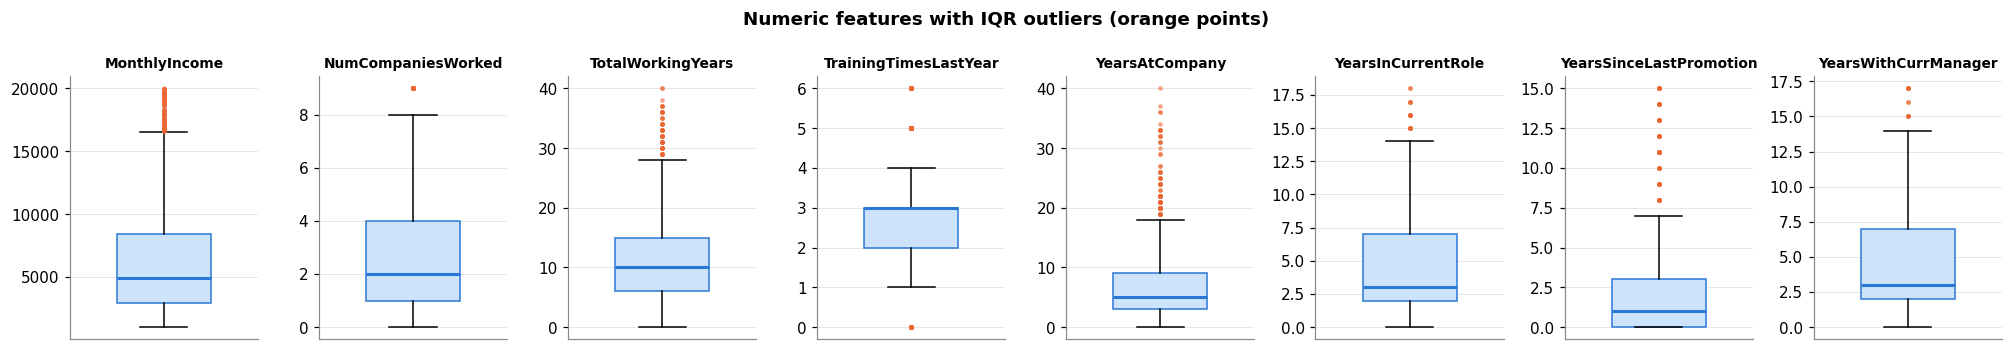

In [14]:
flag = out[out.n_outliers > 0].index.tolist()
fig, axes = plt.subplots(1, len(flag), figsize=(2.3 * len(flag), 3.2))
for ax, c in zip(np.atleast_1d(axes), flag):
    ax.boxplot(df[c], widths=.5, patch_artist=True, boxprops=dict(facecolor="#cde2fb", edgecolor=C_STAY),
               medianprops=dict(color=C_STAY, lw=2), flierprops=dict(marker="o", ms=3, mfc=C_LEFT, mec="none", alpha=.6))
    ax.set_title(c, fontsize=9); ax.set_xticks([])
fig.suptitle("Numeric features with IQR outliers (orange points)", fontweight="bold")
plt.tight_layout(); save(fig, "outliers_boxplots"); plt.show()

**Observations.** 
- 8 of the 14 numeric features have IQR outliers. The most affected are `TrainingTimesLastYear` (16.2%, but only because 0 and 5–6 trainings fall outside a narrow IQR of 2–3), `MonthlyIncome` (7.8%), `YearsSinceLastPromotion` (7.3%) and `YearsAtCompany` (7.1%).
- **These outliers are real, valid values**: senior managers earning ~20k, employees with 30+ years of tenure. They are not data-entry errors, and all tenure consistency checks passed with 0 violations. Deleting them would remove exactly the senior, long-tenured employees who rarely leave, and would bias the model.
- **Decision: keep all rows** and reduce the outliers' leverage with a `log1p` transform on the skewed features (Section 7) plus standardisation and L2 regularisation. The effect is measured in the experiments.


### 5.6 Encoding & scaling plan
- **Nominal** features → **one-hot encoding** with the first level dropped (`drop='first'`) to avoid the dummy-variable trap in Logistic Regression.
- **Ordinal** features (1–4 / 1–5 scales) → kept as **integers**: their order is meaningful and one-hot encoding the scales would add ~15 extra columns for only ~190 training leavers. (Tested as an experiment in Section 8.)
- **Numeric** features → **standardised** (`StandardScaler`). Logistic Regression with regularisation is scale-sensitive: without scaling the penalty treats a 1-unit change in income and in age identically, and the solver converges poorly. Scaling also makes coefficients comparable.
- **Right-skewed monetary/tenure features** → `log1p` transform (Section 7), which reduces the leverage of the extreme values found above.
- All encoders and scalers are fitted **inside a scikit-learn Pipeline on the training folds only**, preventing data leakage from the test set.

### 5.7 Proposed workflow, modelling approach & evaluation plan
1. **Preprocessing** — done above: no missing values/duplicates expected; drop constants/ID; correct dtypes; outliers kept but log-transformed.
2. **EDA** — attrition rate by each categorical variable, distributions of numeric variables by attrition, correlation analysis, statistical tests (Chi-square, Mann-Whitney U).
3. **Feature engineering** — tenure ratios, promotion gap, income relative to job level, composite satisfaction, early-tenure flag, log transforms.
4. **Feature selection** — remove zero-signal and highly collinear features using statistical tests, mutual information, correlation and VIF, and L1-regularised Logistic Regression.
5. **Modelling** — stratified 80/20 train-test split; a majority-class dummy as reference; baseline Logistic Regression on minimally processed features; controlled experiments adding one change at a time (engineered features, feature selection, class weighting) compared with 5-fold stratified cross-validation.
6. **Limited tuning** — regularisation strength `C`, penalty (L1/L2) and `class_weight`.
7. **Evaluation** — ROC-AUC and PR-AUC (threshold-free, suited to imbalance), recall/precision/F1 for the positive class, confusion matrix, threshold analysis with a simple cost model, calibration, odds-ratio interpretation, and a group-level fairness check.

## 6. Exploratory Data Analysis (EDA)
EDA answers: *how imbalanced is the target, which variables separate leavers from stayers, and how do the variables relate to each other?*

### 6.1 Target distribution

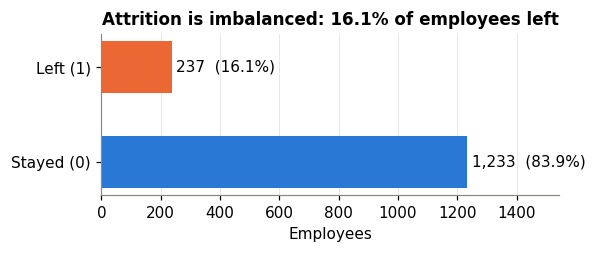

Imbalance ratio (stayed : left) = 5.2 : 1
A model that always predicts 'stay' would already be 83.9% accurate -> accuracy is not a useful headline metric.


In [15]:
counts = df["Attrition"].value_counts().sort_index()
rate = df["Attrition"].mean()
fig, ax = plt.subplots(figsize=(5.5, 2.4))
ax.barh(["Stayed (0)", "Left (1)"], counts.values, color=[C_STAY, C_LEFT], height=.55)
for i, v in enumerate(counts.values):
    ax.text(v + 15, i, f"{v:,}  ({v / len(df):.1%})", va="center")
ax.set_xlim(0, counts.max() * 1.25); ax.set_xlabel("Employees"); ax.grid(axis="y", visible=False)
ax.set_title(f"Attrition is imbalanced: {rate:.1%} of employees left")
plt.tight_layout(); save(fig, "target_distribution"); plt.show()
print(f"Imbalance ratio (stayed : left) = {counts[0] / counts[1]:.1f} : 1")
print(f"A model that always predicts 'stay' would already be {1 - rate:.1%} accurate -> accuracy is not a useful headline metric.")

**Observations.** 
- Only **16.1%** of employees left (237 of 1,470): an imbalance of about **5.2 : 1**.
- A trivial "nobody leaves" model scores 83.9% accuracy while catching zero leavers. The project therefore evaluates with **ROC-AUC, PR-AUC, recall, precision and F1 for the 'Left' class**, and uses **stratified** splits so every fold keeps the 16% rate.
- Imbalance is handled by tuning the decision threshold, and `class_weight='balanced'` is tested as an alternative (Sections 8–10). Neither changes the data itself (no over- or under-sampling).


### 6.2 Attrition rate by categorical and ordinal variables

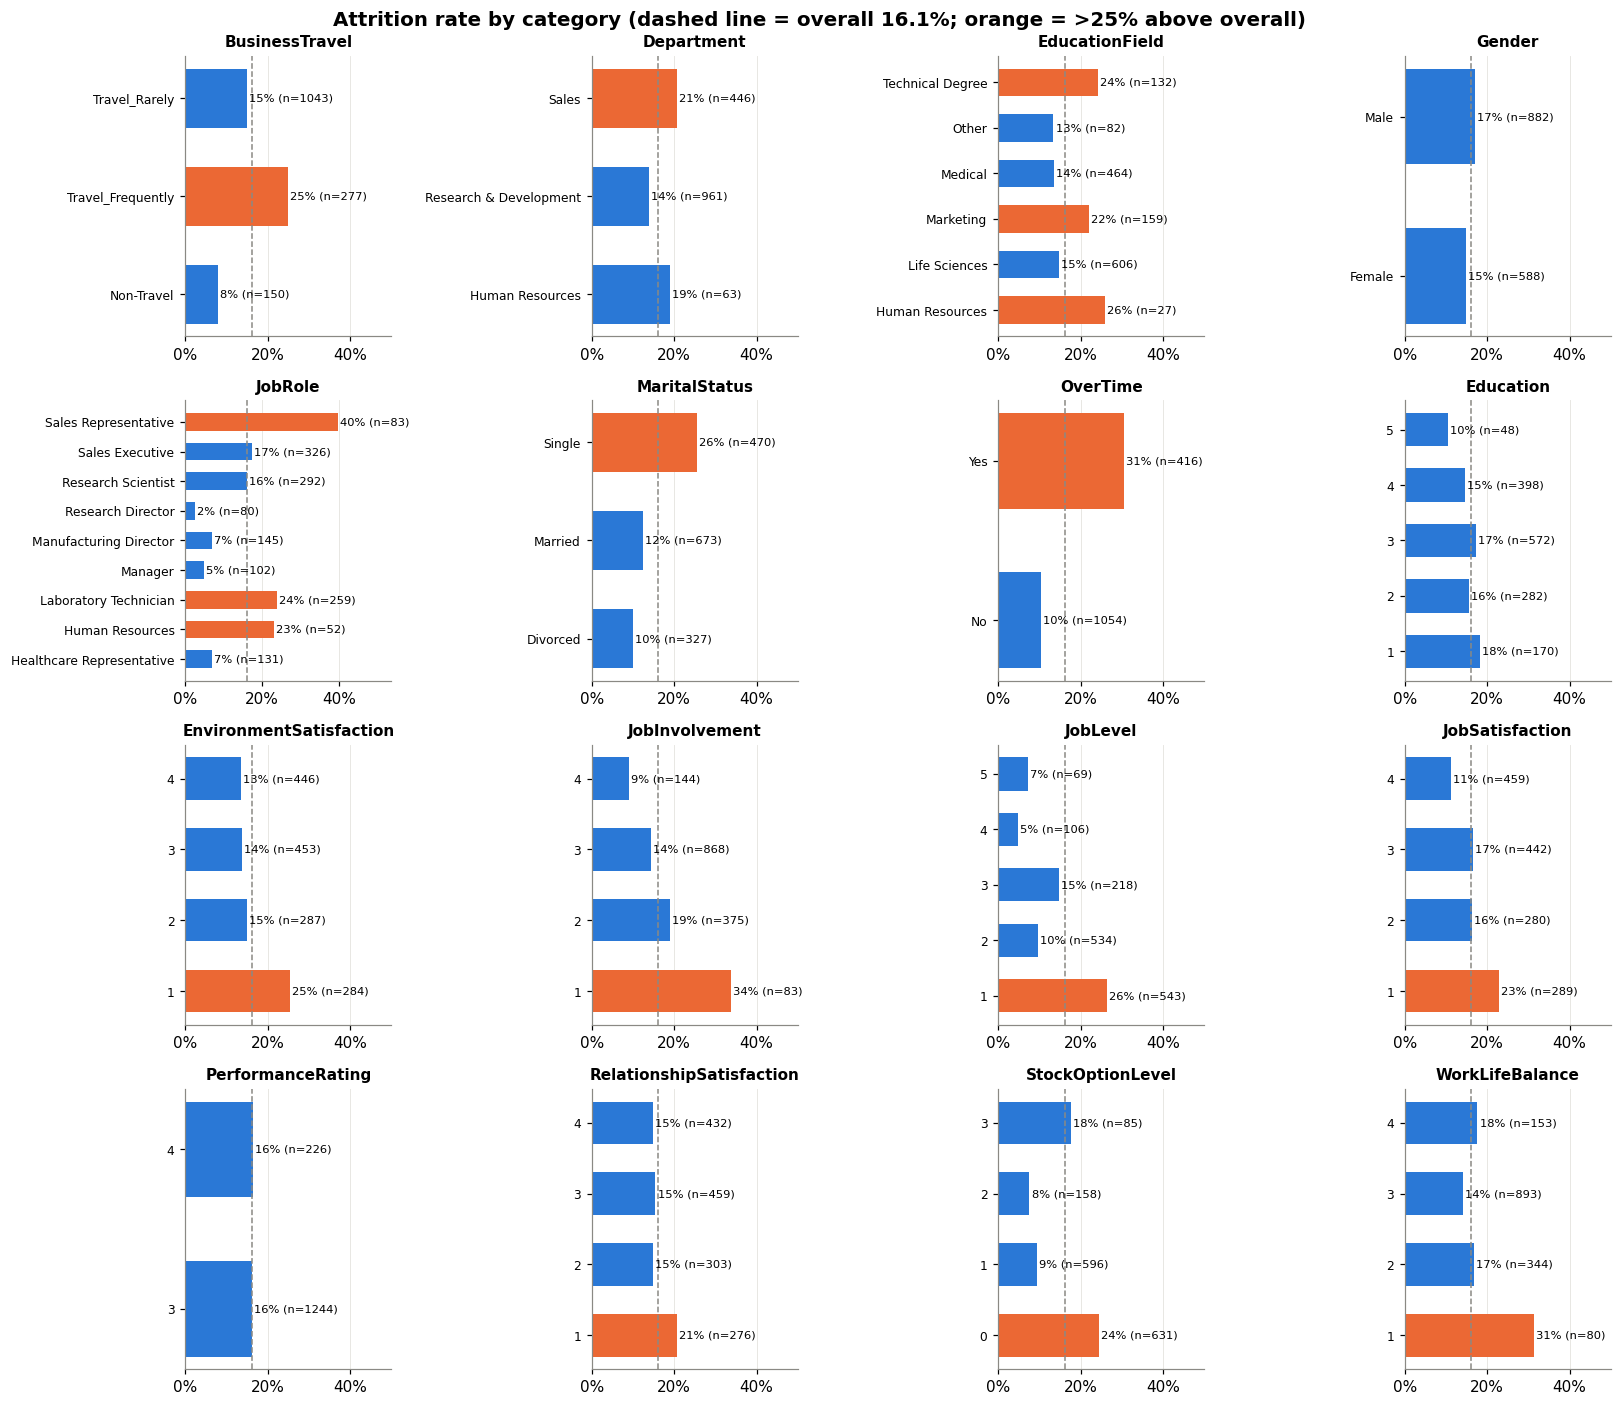

In [16]:
def rate_table(col):
    g = df.groupby(col, observed=True)["Attrition"].agg(["mean", "size"]).rename(columns={"mean": "rate", "size": "n"})
    return g
cat_like = nominal_cols + ordinal_cols
fig, axes = plt.subplots(4, 4, figsize=(15, 13))
for ax, c in zip(axes.ravel(), cat_like):
    g = rate_table(c)
    cols = [C_LEFT if r > rate * 1.25 else C_STAY for r in g.rate]
    ax.barh(g.index.astype(str), g.rate, color=cols, height=.6)
    ax.axvline(rate, color=C_NEUTRAL, ls="--", lw=1)
    for i, (r, n) in enumerate(zip(g.rate, g.n)):
        ax.text(r + .005, i, f"{r:.0%} (n={n})", va="center", fontsize=7.5)
    ax.set_title(c, fontsize=10); ax.set_xlim(0, max(.5, g.rate.max() * 1.35)); ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
for ax in axes.ravel()[len(cat_like):]: ax.axis("off")
fig.suptitle(f"Attrition rate by category (dashed line = overall {rate:.1%}; orange = >25% above overall)", fontsize=13, fontweight="bold")
plt.tight_layout(); save(fig, "attrition_rate_by_category"); plt.show()

**Statistical test.** The chart shows the size of each effect; the Chi-square test tells us whether the association with attrition is larger than chance (p < 0.05), and Cramér's V gives its strength (0 = none, 1 = perfect).

In [17]:
# Chi-square test of independence for every categorical/ordinal feature vs Attrition
chi_rows = []
for c in cat_like:
    ct = pd.crosstab(df[c], df["Attrition"])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    chi_rows.append((c, chi2, dof, p, cramers_v))
chi_df = pd.DataFrame(chi_rows, columns=["feature", "chi2", "dof", "p_value", "cramers_v"]).set_index("feature")
chi_df["significant (p<0.05)"] = chi_df.p_value < 0.05
chi_df.sort_values("cramers_v", ascending=False).round(4)

,chi2,dof,p_value,cramers_v,significant (p<0.05)
feature,,,,,
OverTime,87.5643,1,0.0000,0.2441,True
JobRole,86.1903,8,0.0000,0.2421,True
JobLevel,72.5290,4,0.0000,0.2221,True
StockOptionLevel,60.5983,3,0.0000,0.2030,True
MaritalStatus,46.1637,2,0.0000,0.1772,True
JobInvolvement,28.4920,3,0.0000,0.1392,True
BusinessTravel,24.1824,2,0.0000,0.1283,True
EnvironmentSatisfaction,22.5039,3,0.0001,0.1237,True
JobSatisfaction,17.5051,3,0.0006,0.1091,True


**Observations.** 
- **OverTime** is the strongest single categorical signal (Cramér's V = 0.24): **30.5%** attrition with overtime vs **10.4%** without, i.e. almost 3× higher.
- **Job role / level:** Sales Representatives (39.8%), Laboratory Technicians (23.9%) and JobLevel 1 (26.3%) are the highest-risk groups. Research Directors (2.5%) and Managers (4.9%) almost never leave.
- **StockOptionLevel 0** (24.4%) and **Single** employees (25.5% vs 10.1% for divorced) show much higher attrition. Having no stock options likely means less financial "lock-in".
- **Frequent travellers** leave at 24.9% vs 8.0% for non-travellers.
- **Survey scores behave as expected and are monotone:** the lowest level of JobInvolvement (33.7%), WorkLifeBalance (31.2%), EnvironmentSatisfaction (25.4%) and JobSatisfaction (22.8%) all roughly double the base rate.
- **Not significant (p > 0.05):** `Gender` (14.8% F vs 17.0% M, p = 0.29), `Education`, `RelationshipSatisfaction` and `PerformanceRating`, the last with almost identical rates. They are candidates for removal.


### 6.3 Numeric variables: distributions by attrition

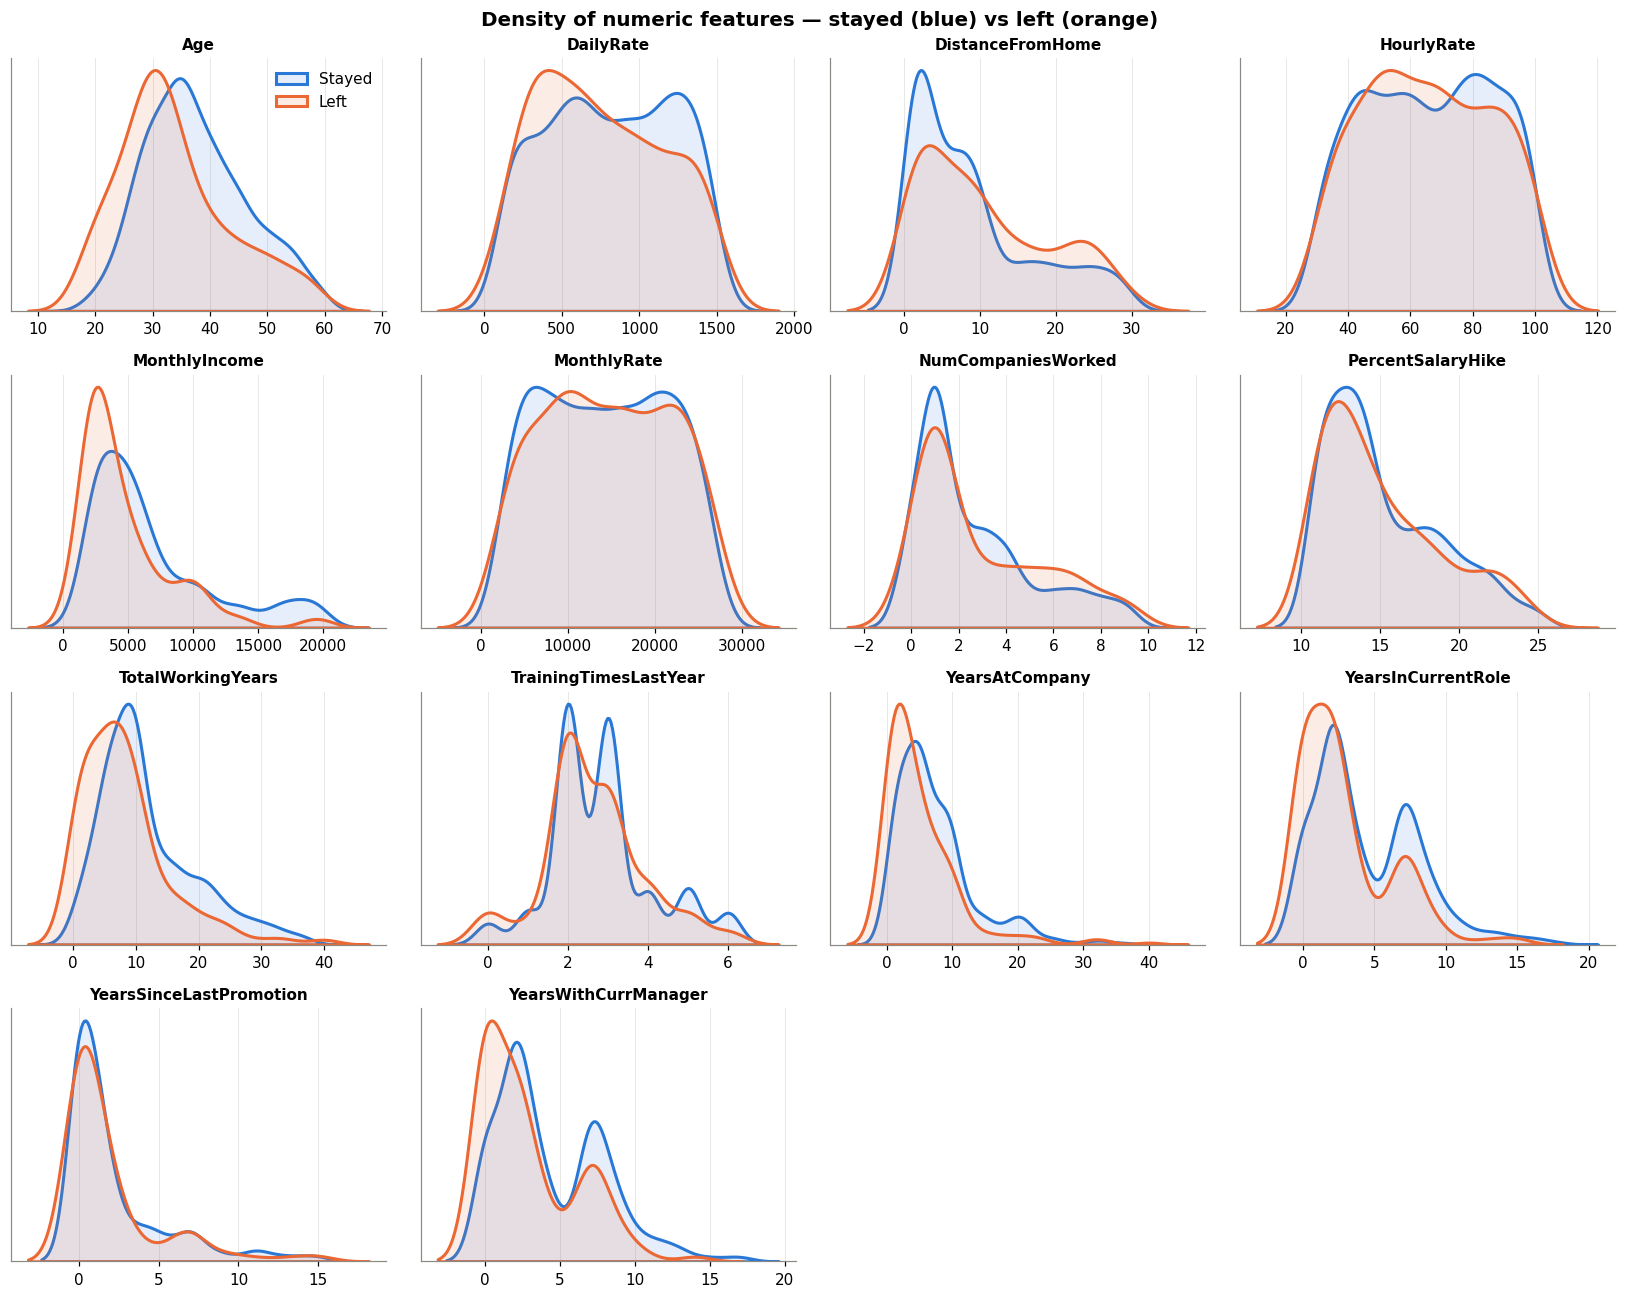

In [18]:
fig, axes = plt.subplots(4, 4, figsize=(15, 12))
for ax, c in zip(axes.ravel(), numeric_cols):
    for lbl, colr, name in [(0, C_STAY, "Stayed"), (1, C_LEFT, "Left")]:
        sns.kdeplot(df.loc[df.Attrition == lbl, c], ax=ax, color=colr, lw=2, fill=True, alpha=.12, label=name, common_norm=False, warn_singular=False)
    ax.set_title(c, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_yticks([])
axes.ravel()[0].legend(frameon=False)
for ax in axes.ravel()[len(numeric_cols):]: ax.axis("off")
fig.suptitle("Density of numeric features — stayed (blue) vs left (orange)", fontsize=13, fontweight="bold")
plt.tight_layout(); save(fig, "numeric_kde_by_attrition"); plt.show()

**Statistical test for numeric features.** Mann-Whitney U compares the two groups without assuming normality; the rank-biserial effect size shows how strongly they differ.

In [19]:
# Mann-Whitney U test (non-parametric; numeric features are skewed so a t-test's normality assumption is doubtful)
mw_rows = []
for c in numeric_cols:
    a, b = df.loc[df.Attrition == 1, c], df.loc[df.Attrition == 0, c]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    r_rb = 1 - 2 * u / (len(a) * len(b))        # rank-biserial effect size (sign: + means stayers higher)
    mw_rows.append((c, a.median(), b.median(), p, r_rb))
mw_df = pd.DataFrame(mw_rows, columns=["feature", "median_left", "median_stayed", "p_value", "effect_size_rb"]).set_index("feature")
mw_df["significant (p<0.05)"] = mw_df.p_value < 0.05
mw_df.reindex(mw_df.effect_size_rb.abs().sort_values(ascending=False).index).round(4)

,median_left,median_stayed,p_value,effect_size_rb,significant (p<0.05)
feature,,,,,
TotalWorkingYears,7.0,10.0,0.0000,0.3117,True
MonthlyIncome,3202.0,5204.0,0.0000,0.3113,True
YearsAtCompany,3.0,6.0,0.0000,0.2979,True
YearsInCurrentRole,2.0,3.0,0.0000,0.2799,True
YearsWithCurrManager,2.0,3.0,0.0000,0.2720,True
Age,32.0,36.0,0.0000,0.2686,True
DistanceFromHome,9.0,7.0,0.0024,-0.1240,True
DailyRate,699.0,817.0,0.0290,0.0894,True
YearsSinceLastPromotion,1.0,1.0,0.0412,0.0803,True


**Observations.** 
- Leavers are **younger** (median age 32 vs 36), **earn less** (median income 3,202 vs 5,204), have **fewer total working years** (7 vs 10) and **shorter tenure** at the company (3 vs 6 years). These four have the largest effect sizes (rank-biserial ≈ 0.27–0.31).
- Leavers live slightly **further from home** (median 9 vs 7).
- `HourlyRate`, `MonthlyRate`, `PercentSalaryHike` and `NumCompaniesWorked` show **no significant difference**. `DailyRate` is only marginally significant (p = 0.03, tiny effect).
- The distributions overlap heavily. No single variable separates the classes, so a multivariate model is needed.


### 6.4 Key relationships

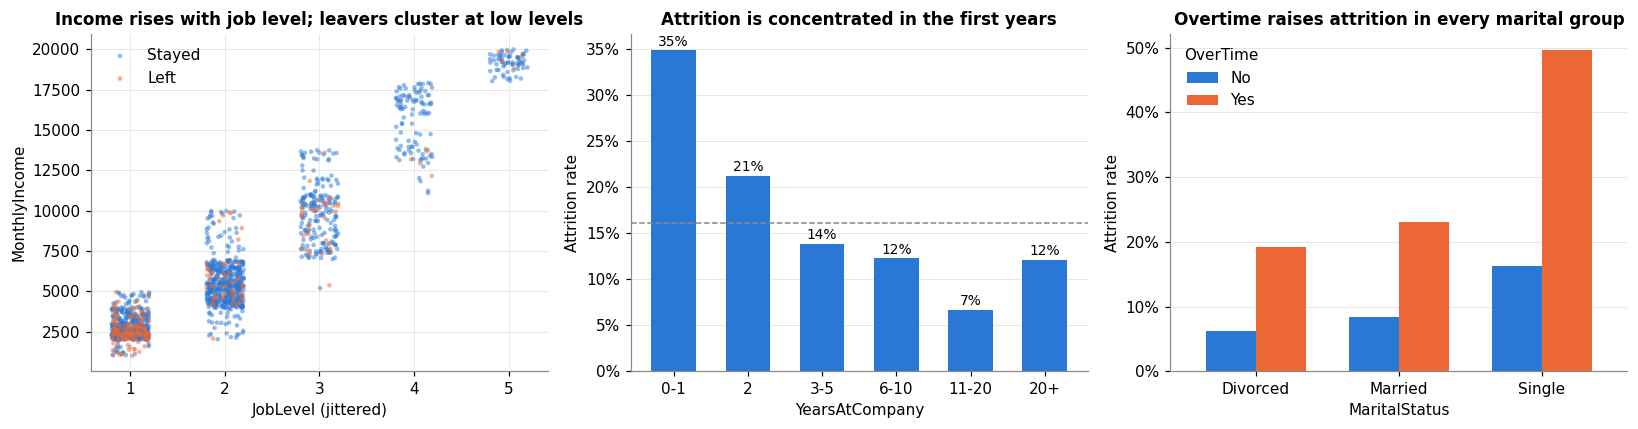

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
# (a) Income vs job level, coloured by attrition
for lbl, colr, name in [(0, C_STAY, "Stayed"), (1, C_LEFT, "Left")]:
    d = df[df.Attrition == lbl]
    axes[0].scatter(d.JobLevel + np.random.uniform(-.2, .2, len(d)), d.MonthlyIncome, s=9, alpha=.5, color=colr, label=name, edgecolors="none")
axes[0].set_xlabel("JobLevel (jittered)"); axes[0].set_ylabel("MonthlyIncome"); axes[0].legend(frameon=False)
axes[0].set_title("Income rises with job level; leavers cluster at low levels")
# (b) Attrition by tenure band
bands = pd.cut(df.YearsAtCompany, [-1, 1, 2, 5, 10, 20, 50], labels=["0-1", "2", "3-5", "6-10", "11-20", "20+"])
g = df.groupby(bands, observed=True).Attrition.mean()
axes[1].bar(g.index.astype(str), g.values, color=C_STAY, width=.6)
for i, v in enumerate(g.values): axes[1].text(i, v + .005, f"{v:.0%}", ha="center", fontsize=9)
axes[1].axhline(rate, color=C_NEUTRAL, ls="--", lw=1); axes[1].set_xlabel("YearsAtCompany"); axes[1].set_ylabel("Attrition rate")
axes[1].set_title("Attrition is concentrated in the first years"); axes[1].grid(axis="x", visible=False)
# (c) OverTime x MaritalStatus interaction
p = df.pivot_table(index="MaritalStatus", columns="OverTime", values="Attrition", aggfunc="mean", observed=True)
p.plot(kind="bar", ax=axes[2], color=[C_STAY, C_LEFT], width=.7, rot=0)
axes[2].set_ylabel("Attrition rate"); axes[2].legend(title="OverTime", frameon=False); axes[2].grid(axis="x", visible=False)
axes[2].set_title("Overtime raises attrition in every marital group")
for ax in axes[1:]: ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.tight_layout(); save(fig, "key_relationships"); plt.show()

**Segment view (business question 4).** Attrition rate of the main risk groups inside each department:

In [21]:
# Do drivers differ by department? Attrition rate for key risk factors within each department
seg = []
for dept, d in df.groupby("Department", observed=True):
    seg.append({"Department": dept, "n": len(d), "overall_rate": d.Attrition.mean(),
                "rate_OverTime=Yes": d.loc[d.OverTime == "Yes", "Attrition"].mean(),
                "rate_OverTime=No": d.loc[d.OverTime == "No", "Attrition"].mean(),
                "rate_JobLevel=1": d.loc[d.JobLevel == 1, "Attrition"].mean(),
                "rate_JobSatisfaction=1": d.loc[d.JobSatisfaction == 1, "Attrition"].mean(),
                "rate_TravelFrequently": d.loc[d.BusinessTravel == "Travel_Frequently", "Attrition"].mean()})
dept_drivers = pd.DataFrame(seg).set_index("Department")
dept_drivers.round(3)

,n,overall_rate,rate_OverTime=Yes,rate_OverTime=No,rate_JobLevel=1,rate_JobSatisfaction=1,rate_TravelFrequently
Department,,,,,,,
Human Resources,63,0.190,0.294,0.152,0.303,0.455,0.364
Research & Development,961,0.138,0.273,0.086,0.233,0.198,0.203
Sales,446,0.206,0.375,0.138,0.421,0.267,0.333


Attrition, overtime, pay and tenure profile of each job role:

In [22]:
role_tab = df.groupby("JobRole", observed=True).agg(n=("Attrition", "size"), attrition_rate=("Attrition", "mean"),
                                                    overtime_share=("OverTime", lambda s: (s == "Yes").mean()),
                                                    median_income=("MonthlyIncome", "median"),
                                                    median_tenure=("YearsAtCompany", "median")).sort_values("attrition_rate", ascending=False)
role_tab.round(3)

,n,attrition_rate,overtime_share,median_income,median_tenure
JobRole,,,,,
Sales Representative,83,0.398,0.289,2579.0,2.0
Laboratory Technician,259,0.239,0.239,2886.0,4.0
Human Resources,52,0.231,0.250,3093.0,5.0
Sales Executive,326,0.175,0.288,6231.0,7.0
Research Scientist,292,0.161,0.332,2887.5,4.5
Manufacturing Director,145,0.069,0.269,6447.0,7.0
Healthcare Representative,131,0.069,0.282,6811.0,7.0
Manager,102,0.049,0.265,17454.5,12.5
Research Director,80,0.025,0.288,16510.0,9.0


**Observations.** 
- **Tenure:** attrition is **35% in the first year** and 21% in year 2, falling to 7% at 11–20 years. The first two years are the critical retention window.
- **Income vs level:** income is almost fully determined by JobLevel (ρ = 0.92), and leavers cluster in levels 1–2.
- **Interaction:** overtime raises attrition in every marital group, but **single employees working overtime leave at ~50%**. Logistic Regression adds effects on the log-odds scale, which captures this compounding reasonably well.
- **Drivers by department:** overtime and entry level are risk factors in *every* department, but their strength differs. In **Sales**, 42% of JobLevel-1 staff and 37.5% of overtime workers leave, vs 23% and 27% in R&D. In **HR** (only 63 people), low job satisfaction is associated with 45% attrition. The same drivers apply everywhere with different intensity, which argues for department (and role) as model inputs rather than separate models; separate models would also be data-starved (HR has 12 leavers in total).


### 6.5 Correlation analysis

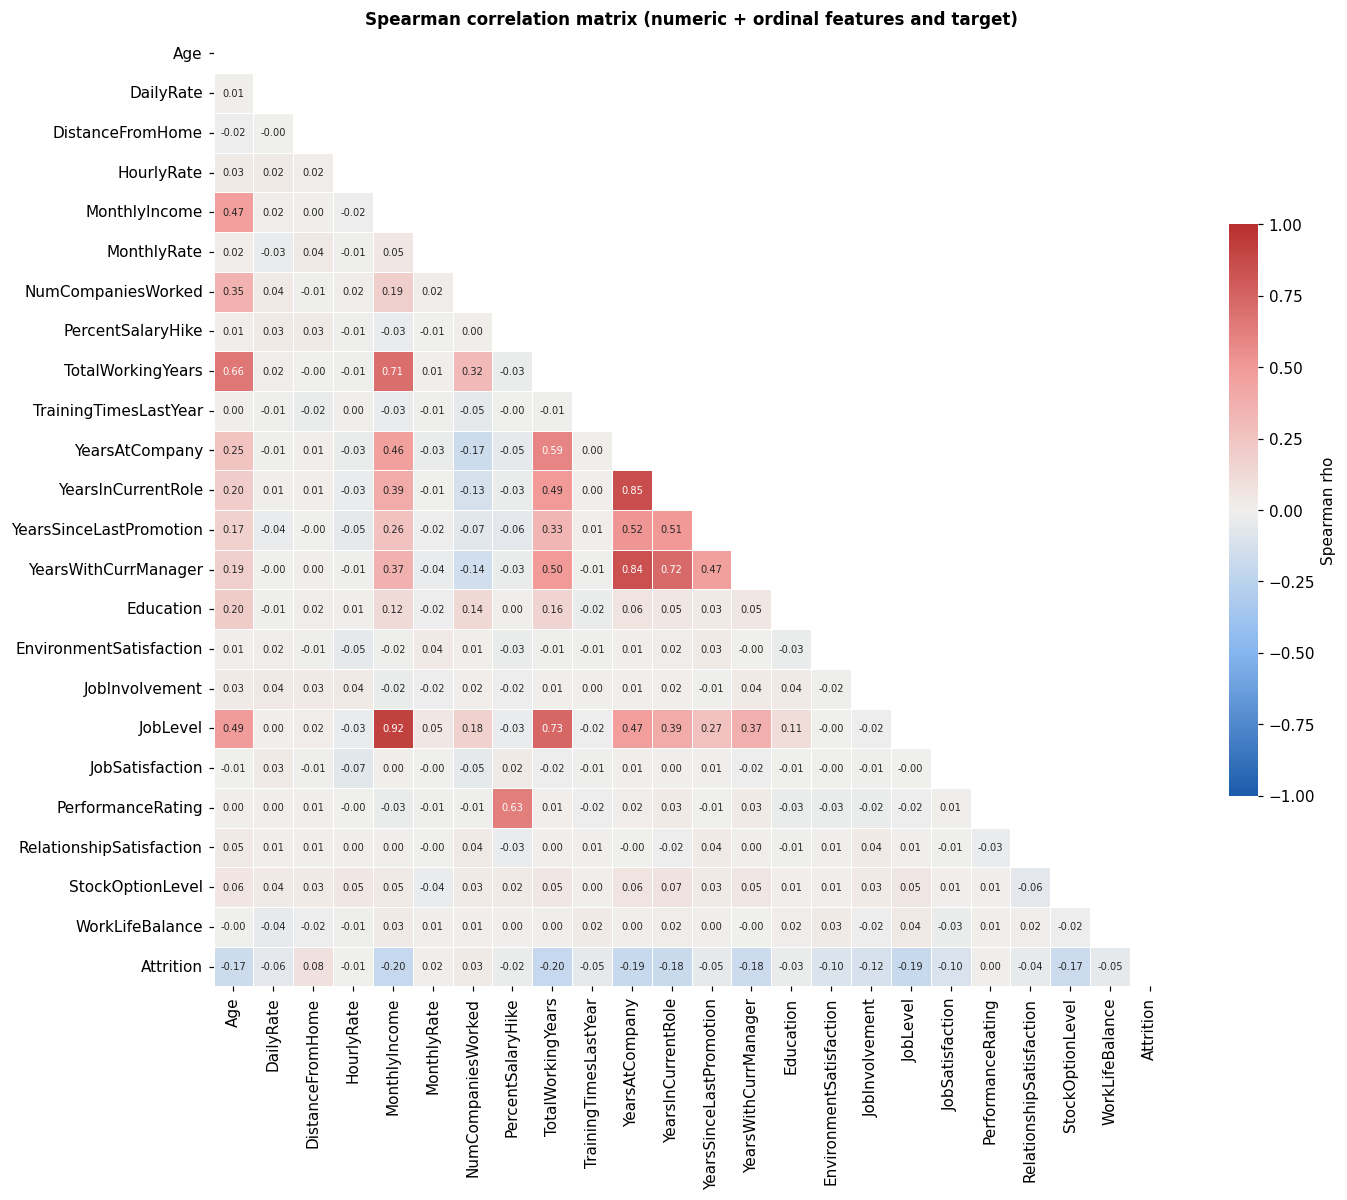

In [23]:
num_ord = numeric_cols + ordinal_cols
corr = df[num_ord + ["Attrition"]].corr(method="spearman")
from matplotlib.colors import LinearSegmentedColormap
div = LinearSegmentedColormap.from_list("bluegrayred", ["#1c5cab", "#86b6ef", "#f0efec", "#f19a98", "#b8302f"])
fig, ax = plt.subplots(figsize=(13, 11))
mask = np.triu(np.ones_like(corr, dtype=bool), k=0); ax.grid(False)
sns.heatmap(corr, mask=mask, cmap=div, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 6.5},
            linewidths=.5, linecolor="white", cbar_kws={"shrink": .6, "label": "Spearman rho"}, ax=ax)
ax.set_title("Spearman correlation matrix (numeric + ordinal features and target)")
plt.tight_layout(); save(fig, "correlation_heatmap"); plt.show()

Listing the strongly correlated pairs explicitly (multicollinearity candidates) and each feature's correlation with the target:

In [24]:
# Strongly correlated pairs (|rho| >= 0.6) -> multicollinearity candidates
pairs = (corr.drop("Attrition").drop(columns="Attrition").where(np.triu(np.ones((len(num_ord),) * 2), 1).astype(bool))
         .stack().rename("rho").reset_index())
pairs = pairs[pairs.rho.abs() >= .6].sort_values("rho", key=abs, ascending=False)
print("Highly correlated pairs:"); display(pairs.round(3))
print("\nCorrelation with Attrition (Spearman):")
corr["Attrition"].drop("Attrition").sort_values().round(3)

Highly correlated pairs:


,level_0,level_1,rho
109,MonthlyIncome,JobLevel,0.920
241,YearsAtCompany,YearsInCurrentRole,0.854
243,YearsAtCompany,YearsWithCurrManager,0.843
201,TotalWorkingYears,JobLevel,0.735
266,YearsInCurrentRole,YearsWithCurrManager,0.725
100,MonthlyIncome,TotalWorkingYears,0.710
8,Age,TotalWorkingYears,0.657
180,PercentSalaryHike,PerformanceRating,0.629



Correlation with Attrition (Spearman):


TotalWorkingYears          -0.199
MonthlyIncome              -0.198
YearsAtCompany             -0.190
JobLevel                   -0.190
YearsInCurrentRole         -0.181
YearsWithCurrManager       -0.175
StockOptionLevel           -0.172
Age                        -0.171
JobInvolvement             -0.119
JobSatisfaction            -0.103
EnvironmentSatisfaction    -0.096
DailyRate                  -0.057
YearsSinceLastPromotion    -0.053
WorkLifeBalance            -0.052
TrainingTimesLastYear      -0.052
RelationshipSatisfaction   -0.043
Education                  -0.030
PercentSalaryHike          -0.024
HourlyRate                 -0.007
PerformanceRating           0.003
MonthlyRate                 0.015
NumCompaniesWorked          0.031
DistanceFromHome            0.079
Name: Attrition, dtype: float64

**Observations.** 
- **Multicollinearity is substantial:** MonthlyIncome–JobLevel (ρ = 0.92), YearsAtCompany–YearsInCurrentRole (0.85), YearsAtCompany–YearsWithCurrManager (0.84), TotalWorkingYears–JobLevel (0.74), Income–TotalWorkingYears (0.71), Age–TotalWorkingYears (0.66) and PercentSalaryHike–PerformanceRating (0.63). Feeding all of them into Logistic Regression would make coefficients unstable and odds ratios uninterpretable, so they are addressed in feature selection.
- **Correlations with the target are individually weak** (|ρ| ≤ 0.20). The strongest are tenure/experience/income/level (all negative) and StockOptionLevel.
- The satisfaction scores are almost uncorrelated with each other (|ρ| < 0.05). Each measures a distinct aspect of engagement, which supports keeping them as separate features and also combining them into a composite.


## 7. Feature Engineering & Feature Selection
### 7.1 New features
Each feature encodes an HR hypothesis that the raw columns only express indirectly:

| New feature | Formula | Hypothesis |
|---|---|---|
| `TenureRatio` | YearsAtCompany / (TotalWorkingYears + 1) | Share of career spent here — loyalty/embeddedness |
| `AvgYearsPerCompany` | TotalWorkingYears / (NumCompaniesWorked + 1) | Job-hopping history |
| `PromotionGapRatio` | YearsSinceLastPromotion / (YearsAtCompany + 1) | Career stagnation relative to tenure |
| `RoleStability` | YearsInCurrentRole / (YearsAtCompany + 1) | Time stuck in the same role |
| `ManagerStability` | YearsWithCurrManager / (YearsAtCompany + 1) | Relationship continuity with manager |
| `IncomeVsLevel` | MonthlyIncome / median income of same JobLevel | Paid below/above peers at the same grade |
| `SatisfactionIndex` | mean of Environment, Job, Relationship satisfaction, JobInvolvement, WorkLifeBalance | Overall engagement in one stable score |
| `LowSatisfactionCount` | number of those 5 scores equal to 1 | Any severe dissatisfaction |
| `EarlyTenure` | 1 if YearsAtCompany ≤ 2 | The high-risk first years (EDA 6.4) |
| `log_*` | log1p of MonthlyIncome, TotalWorkingYears, YearsAtCompany, YearsSinceLastPromotion, DistanceFromHome | Reduce right skew and outlier leverage |

Note: `IncomeVsLevel` uses job-level medians; to avoid leakage the medians are computed from the **training set only** inside a custom transformer.

In [25]:
from sklearn.base import BaseEstimator, TransformerMixin
SAT = ["EnvironmentSatisfaction", "JobSatisfaction", "RelationshipSatisfaction", "JobInvolvement", "WorkLifeBalance"]
LOG_COLS = ["MonthlyIncome", "TotalWorkingYears", "YearsAtCompany", "YearsSinceLastPromotion", "DistanceFromHome"]

class FeatureEngineer(BaseEstimator, TransformerMixin):
    # Adds engineered features. Level medians are learned in fit() -> no leakage from validation/test rows.
    def __init__(self, log_transform=True):
        self.log_transform = log_transform
    def fit(self, X, y=None):
        self.level_median_ = X.groupby("JobLevel")["MonthlyIncome"].median()
        return self
    def transform(self, X):
        X = X.copy()
        X["TenureRatio"] = X.YearsAtCompany / (X.TotalWorkingYears + 1)
        X["AvgYearsPerCompany"] = X.TotalWorkingYears / (X.NumCompaniesWorked + 1)
        X["PromotionGapRatio"] = X.YearsSinceLastPromotion / (X.YearsAtCompany + 1)
        X["RoleStability"] = X.YearsInCurrentRole / (X.YearsAtCompany + 1)
        X["ManagerStability"] = X.YearsWithCurrManager / (X.YearsAtCompany + 1)
        X["IncomeVsLevel"] = X.MonthlyIncome / X.JobLevel.map(self.level_median_).fillna(X.MonthlyIncome.median())
        X["SatisfactionIndex"] = X[SAT].mean(axis=1)
        X["LowSatisfactionCount"] = (X[SAT] == 1).sum(axis=1)
        X["EarlyTenure"] = (X.YearsAtCompany <= 2).astype(int)
        if self.log_transform:
            for c in LOG_COLS:
                X["log_" + c] = np.log1p(X[c])
            X = X.drop(columns=LOG_COLS)
        return X

X_all = df.drop(columns="Attrition"); y_all = df["Attrition"]
fe_preview = FeatureEngineer().fit(X_all).transform(X_all)
new_feats = ["TenureRatio", "AvgYearsPerCompany", "PromotionGapRatio", "RoleStability", "ManagerStability",
             "IncomeVsLevel", "SatisfactionIndex", "LowSatisfactionCount", "EarlyTenure"] + ["log_" + c for c in LOG_COLS]
fe_preview[new_feats].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
TenureRatio,1470.0,0.582,0.284,0.000,0.368,0.636,0.833,0.976
AvgYearsPerCompany,1470.0,4.193,4.036,0.000,1.600,3.000,5.000,38.000
PromotionGapRatio,1470.0,0.236,0.269,0.000,0.000,0.143,0.429,0.917
RoleStability,1470.0,0.481,0.274,0.000,0.333,0.500,0.667,0.882
ManagerStability,1470.0,0.466,0.277,0.000,0.286,0.500,0.667,0.895
IncomeVsLevel,1470.0,1.022,0.247,0.378,0.860,1.000,1.122,1.872
SatisfactionIndex,1470.0,2.731,0.429,1.200,2.400,2.800,3.000,4.000
LowSatisfactionCount,1470.0,0.688,0.767,0.000,0.000,1.000,1.000,4.000
EarlyTenure,1470.0,0.233,0.423,0.000,0.000,0.000,0.000,1.000
log_MonthlyIncome,1470.0,8.553,0.664,6.918,7.977,8.501,9.034,9.903


**Effect of the log transform** on the skewed features:

,skew_before,skew_after_log1p
MonthlyIncome,1.37,0.29
TotalWorkingYears,1.12,-0.62
YearsAtCompany,1.76,-0.21
YearsSinceLastPromotion,1.98,0.72
DistanceFromHome,0.96,-0.03


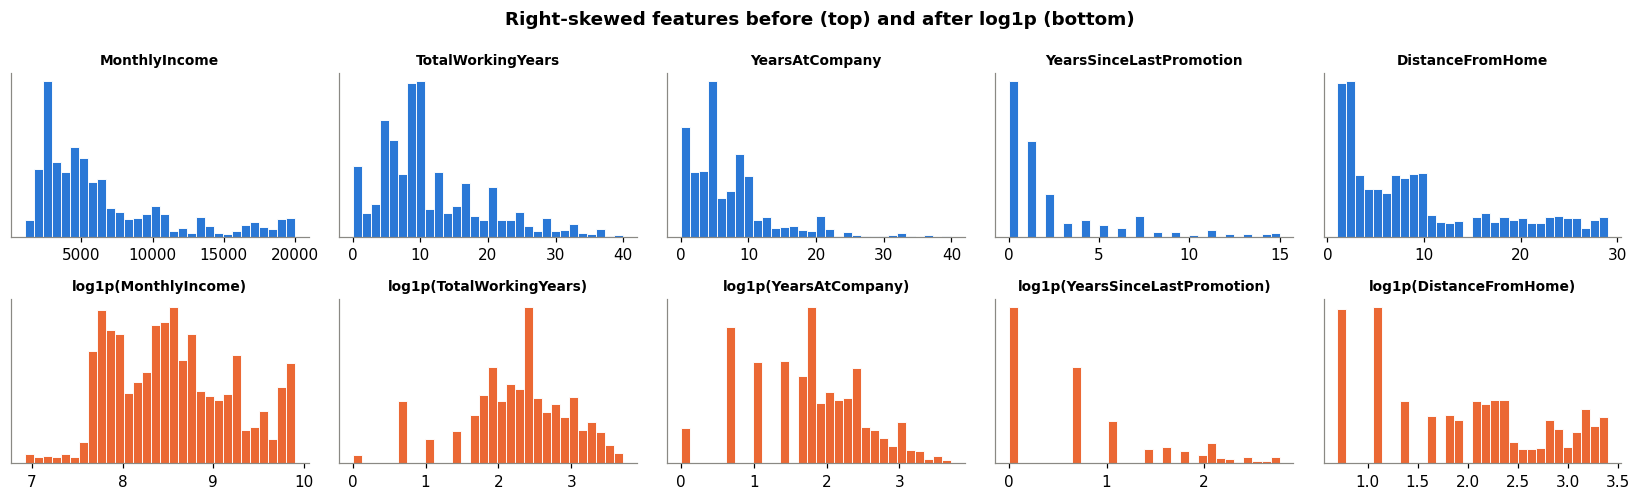

In [26]:
# Skewness before vs after log transform
sk = pd.DataFrame({"skew_before": [df[c].skew() for c in LOG_COLS],
                   "skew_after_log1p": [fe_preview["log_" + c].skew() for c in LOG_COLS]}, index=LOG_COLS)
display(sk.round(2))
fig, axes = plt.subplots(2, len(LOG_COLS), figsize=(15, 4.6))
for j, c in enumerate(LOG_COLS):
    axes[0, j].hist(df[c], bins=30, color=C_STAY, edgecolor="white", linewidth=.6); axes[0, j].set_title(c, fontsize=9)
    axes[1, j].hist(fe_preview["log_" + c], bins=30, color=C_LEFT, edgecolor="white", linewidth=.6); axes[1, j].set_title("log1p(" + c + ")", fontsize=9)
    for a in axes[:, j]: a.set_yticks([]); a.grid(visible=False)
fig.suptitle("Right-skewed features before (top) and after log1p (bottom)", fontweight="bold")
plt.tight_layout(); save(fig, "log_transform"); plt.show()

**Testing each engineered feature** — does it actually differ between leavers and stayers?

In [27]:
# Does each engineered feature separate leavers from stayers? (Mann-Whitney effect size + attrition rate by quartile)
eng_rows = []
for c in new_feats:
    a, b = fe_preview.loc[y_all == 1, c], fe_preview.loc[y_all == 0, c]
    u, p = stats.mannwhitneyu(a, b)
    eng_rows.append((c, a.median(), b.median(), p, 1 - 2 * u / (len(a) * len(b))))
eng_df = pd.DataFrame(eng_rows, columns=["feature", "median_left", "median_stayed", "p_value", "effect_size_rb"]).set_index("feature")
eng_df.reindex(eng_df.effect_size_rb.abs().sort_values(ascending=False).index).round(4)

,median_left,median_stayed,p_value,effect_size_rb
feature,,,,
AvgYearsPerCompany,1.6250,3.3333,0.0000,0.3649
log_TotalWorkingYears,2.0794,2.3979,0.0000,0.3117
log_MonthlyIncome,8.0718,8.5574,0.0000,0.3113
log_YearsAtCompany,1.3863,1.9459,0.0000,0.2979
SatisfactionIndex,2.6000,2.8000,0.0000,0.2798
LowSatisfactionCount,1.0000,0.0000,0.0000,-0.2657
EarlyTenure,0.0000,0.0000,0.0000,-0.2357
RoleStability,0.4286,0.5294,0.0000,0.2223
ManagerStability,0.4667,0.5000,0.0000,0.2025


Attrition rate across quartiles of the most interesting engineered features:

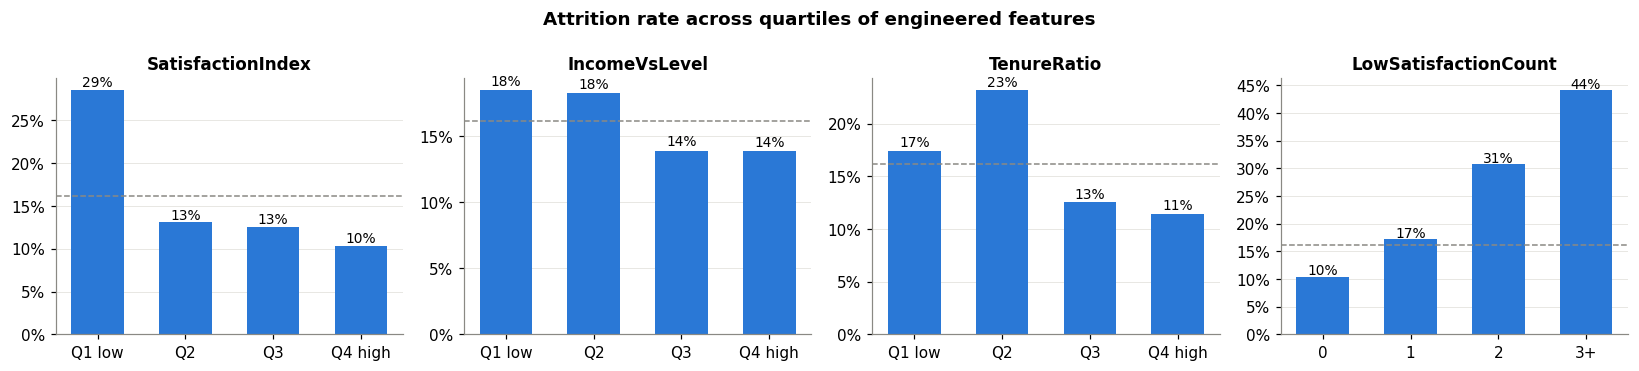

In [28]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, c in zip(axes, ["SatisfactionIndex", "IncomeVsLevel", "TenureRatio", "LowSatisfactionCount"]):
    q = pd.qcut(fe_preview[c].rank(method="first"), 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"]) if c != "LowSatisfactionCount" else fe_preview[c].clip(upper=3).astype(str).replace({"3": "3+"})
    g = y_all.groupby(q, observed=True).mean()
    ax.bar(g.index.astype(str), g.values, color=C_STAY, width=.6)
    for i, v in enumerate(g.values): ax.text(i, v + .004, f"{v:.0%}", ha="center", fontsize=9)
    ax.axhline(rate, color=C_NEUTRAL, ls="--", lw=1); ax.set_title(c); ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_locator(plt.MultipleLocator(.05)); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
fig.suptitle("Attrition rate across quartiles of engineered features", fontweight="bold")
plt.tight_layout(); save(fig, "engineered_features"); plt.show()

**Observations.** 
- The log transform works as intended: skewness drops from 1.37 → 0.29 (MonthlyIncome), 1.76 → −0.21 (YearsAtCompany) and 0.96 → −0.03 (DistanceFromHome).
- **`AvgYearsPerCompany` is the strongest single feature in the whole dataset** (effect size 0.36, above any raw column). Leavers average 1.6 years per employer vs 3.3 for stayers, so job-hopping history is highly predictive.
- **`SatisfactionIndex`** (0.28) and **`LowSatisfactionCount`** (0.27) separate the classes better than any individual survey score (the best raw score was ~0.14). Aggregating the weak individual signals made them stronger.
- `RoleStability`, `ManagerStability`, `TenureRatio` and `IncomeVsLevel` are significant but moderate. `TenureRatio` is non-monotone (Q2 has the highest rate, 23%), which a linear term only partly captures. `IncomeVsLevel` shows that leavers are paid slightly below the median of their own grade.
- **`PromotionGapRatio` is not significant (p = 0.52)**. This hypothesis was not supported, and the feature is dropped in selection.


### 7.2 Feature selection
Four complementary lenses are combined, rather than trusting any single one:
1. **Statistical relevance** — Chi-square (categorical) and Mann-Whitney U (numeric) p-values from EDA.
2. **Mutual information** — captures non-linear dependence with the target.
3. **Multicollinearity** — Variance Inflation Factor (VIF); VIF > 5–10 means a feature is largely explained by the others, which inflates Logistic Regression coefficient variance and makes odds ratios unreliable.
4. **L1 (Lasso) Logistic Regression** — an embedded method that shrinks uninformative coefficients to exactly zero.

To keep the test set untouched, selection is carried out on the **training split only**. The split is therefore made here.

In [29]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_all, y_all, test_size=0.20, stratify=y_all, random_state=RANDOM_STATE)
print("Train:", X_train_raw.shape, f"attrition={y_train.mean():.3f}")
print("Test :", X_test_raw.shape, f"attrition={y_test.mean():.3f}")
fe = FeatureEngineer().fit(X_train_raw)
Xtr_fe = fe.transform(X_train_raw)

Train: (1176, 30) attrition=0.162
Test : (294, 30) attrition=0.160


**Lens 2 — mutual information** (captures any kind of dependence, not only linear):

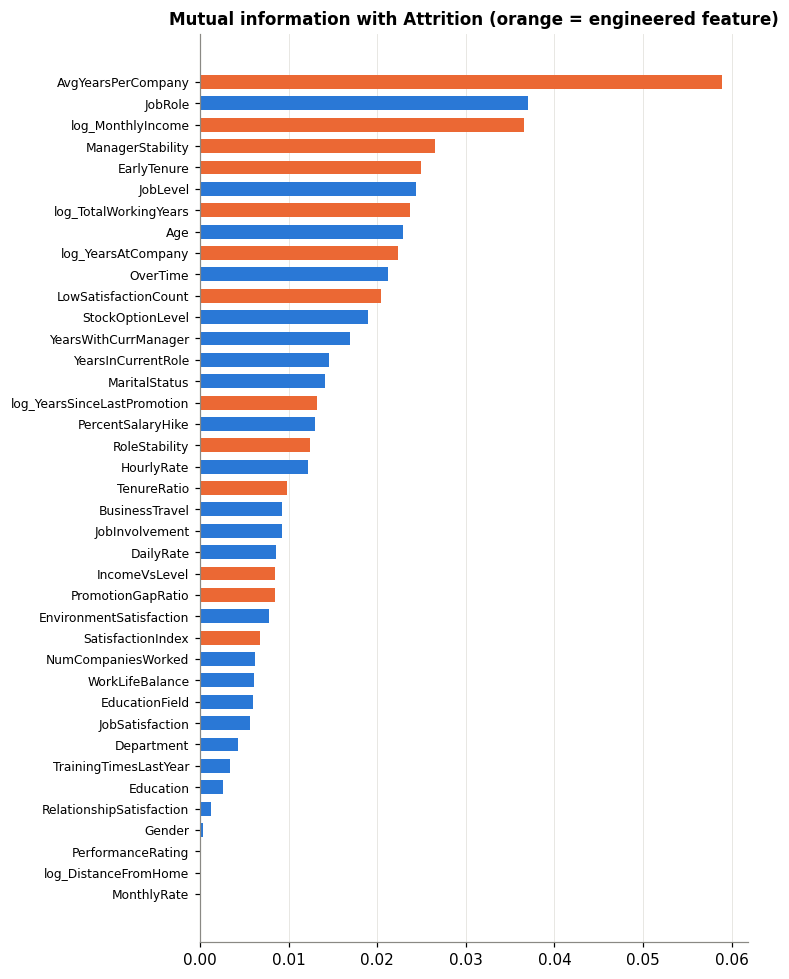

In [30]:
# Mutual information (discrete flags for categoricals; numeric features are used as-is)
Xmi = Xtr_fe.copy()
for c in nominal_cols: Xmi[c] = Xmi[c].cat.codes
disc = [c in nominal_cols or c in ordinal_cols or c in ("EarlyTenure", "LowSatisfactionCount") for c in Xmi.columns]
mi = pd.Series(mutual_info_classif(Xmi, y_train, discrete_features=disc, random_state=RANDOM_STATE), index=Xmi.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 9))
ax.barh(mi.index, mi.values, color=[C_LEFT if c in new_feats else C_STAY for c in mi.index], height=.65)
ax.set_title("Mutual information with Attrition (orange = engineered feature)"); ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); save(fig, "mutual_information"); plt.show()

**Lens 3 — multicollinearity (VIF)** on all numeric/ordinal candidates before selection:

In [31]:
# VIF computed from R^2 of regressing each numeric/ordinal feature on all others: VIF = 1 / (1 - R^2)
def vif_table(X):
    X = (X - X.mean()) / X.std()
    out = {}
    for c in X.columns:
        others = X.drop(columns=c)
        r2 = LinearRegression().fit(others, X[c]).score(others, X[c])
        out[c] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(out, name="VIF").sort_values(ascending=False)
num_fe = [c for c in Xtr_fe.columns if c not in nominal_cols]
vif_before = vif_table(Xtr_fe[num_fe])
vif_before.round(2).head(15)

EnvironmentSatisfaction          inf
JobInvolvement                   inf
JobSatisfaction                  inf
WorkLifeBalance                  inf
RelationshipSatisfaction         inf
SatisfactionIndex                inf
log_MonthlyIncome              37.36
JobLevel                       34.92
log_YearsAtCompany             25.64
log_YearsSinceLastPromotion    13.52
PromotionGapRatio              10.94
TenureRatio                    10.80
YearsWithCurrManager           10.40
YearsInCurrentRole              9.59
log_TotalWorkingYears           7.93
Name: VIF, dtype: float64

**Selection decisions** — each removal is justified by the evidence above; VIF is recomputed on the kept set to confirm collinearity is resolved.

In [32]:
# ---- Selection decisions (documented, evidence-based) ----
drop_noise = ["DailyRate", "HourlyRate", "MonthlyRate"]           # undocumented 'rates': no relationship with income or target
drop_collinear = ["JobLevel",                                    # rho~0.9 with income; income + IncomeVsLevel keep the pay signal
                  "log_TotalWorkingYears",                        # collinear with Age and tenure
                  "YearsInCurrentRole", "YearsWithCurrManager",   # collinear with YearsAtCompany; replaced by stability ratios
                  "PercentSalaryHike"]                            # PerformanceRating is set by it (rho~0.77); both weak
drop_fairness = ["Gender"]                                       # protected attribute: excluded from the model, kept for audit
drop_redundant = ["SatisfactionIndex",                           # exact linear combination of the 5 scores (VIF = inf); scores kept as distinct HR levers
                  "PromotionGapRatio",                            # not significant (Mann-Whitney p~0.52) and collinear with promotion/tenure logs
                  "EarlyTenure"]                                  # binary cut of log_YearsAtCompany: redundant, raises its VIF

keep = [c for c in Xtr_fe.columns if c not in drop_noise + drop_collinear + drop_fairness + drop_redundant]
vif_after = vif_table(Xtr_fe[[c for c in keep if c not in nominal_cols]])
print(f"Features: {Xtr_fe.shape[1]} engineered+raw -> {len(keep)} kept")
print(f"Before selection: {int(np.isinf(vif_before).sum())} features with infinite VIF (perfect collinearity), {int((vif_before > 10).sum())} with VIF > 10")
print(f"After selection : max VIF = {vif_after.max():.2f}, features with VIF > 10 = {int((vif_after > 10).sum())}")
vif_after.round(2).head(10)

Features: 39 engineered+raw -> 27 kept
Before selection: 6 features with infinite VIF (perfect collinearity), 13 with VIF > 10
After selection : max VIF = 9.61, features with VIF > 10 = 0


log_YearsAtCompany             9.61
TenureRatio                    6.72
AvgYearsPerCompany             2.94
NumCompaniesWorked             2.50
LowSatisfactionCount           2.30
log_MonthlyIncome              2.26
Age                            2.02
RoleStability                  1.59
ManagerStability               1.57
log_YearsSinceLastPromotion    1.48
Name: VIF, dtype: float64

Evidence that DailyRate, HourlyRate and MonthlyRate carry no signal:

In [33]:
# Evidence for the noise columns: correlation with income and with the target
evidence = pd.DataFrame({c: {"rho_with_MonthlyIncome": stats.spearmanr(df[c], df.MonthlyIncome)[0],
                             "rho_with_Attrition": stats.spearmanr(df[c], df.Attrition)[0],
                             "MannWhitney_p": mw_df.loc[c, "p_value"]} for c in drop_noise}).T
evidence.round(4)

,rho_with_MonthlyIncome,rho_with_Attrition,MannWhitney_p
DailyRate,0.0163,-0.0570,0.0290
HourlyRate,-0.0198,-0.0067,0.7976
MonthlyRate,0.0543,0.0153,0.5587


**Observations.** 
- **Noise features removed:** `DailyRate`, `HourlyRate` and `MonthlyRate` have essentially zero correlation with MonthlyIncome (|ρ| ≤ 0.05) and with Attrition. They are not real pay measures, and keeping them only adds variance.
- **Collinearity removed:** 6 features had *infinite* VIF (`SatisfactionIndex` is an exact linear combination of the 5 scores) and 13 had VIF > 10. After dropping `JobLevel`, `log_TotalWorkingYears`, `YearsInCurrentRole`, `YearsWithCurrManager`, `PercentSalaryHike`, `SatisfactionIndex`, `PromotionGapRatio` and `EarlyTenure`, the **maximum VIF is 9.6** and no feature exceeds 10. The information is not lost: the stability ratios replace the collinear tenure counts, and income plus IncomeVsLevel carry the pay signal.
- **Fairness:** `Gender` is excluded. It is not predictive (p = 0.29), and using it to target retention would be ethically and legally problematic. It is kept only for the fairness audit.
- Result: **39 candidate features → 27 kept** (41 model inputs after one-hot encoding). L1 regularisation is used in tuning as a further embedded selection check.


## 8. Model Construction
### 8.1 Model inputs, outputs and assumptions
- **Input:** a row of employee attributes → encoded into a numeric vector **x** (one-hot nominal, scaled numeric/ordinal).
- **Output:** p = P(Attrition = 1 | x) = 1 / (1 + e^-(b0 + b·x)) — a probability between 0 and 1. A class label is obtained by comparing p to a threshold (0.5 by default, tuned in Section 10.1).
- **Interpretation:** each coefficient b_j is the change in **log-odds** of leaving for a one-unit (here: one standard deviation) increase in feature j, holding others fixed; e^(b_j) is the **odds ratio**.
- **Assumptions:** (i) binary outcome ✔; (ii) independent observations — one row per employee ✔; (iii) little multicollinearity — addressed with VIF (Section 7.2); (iv) linear relationship between each continuous predictor and the log-odds — checked below and supported by log transforms; (v) no extreme influential outliers — mitigated by log transforms and regularisation; (vi) adequate sample size — ~190 leavers in the training set for 41 model inputs is only ~4.6 events per input, below the common guideline of ~10 events per variable. This is the main reason for using regularisation and feature selection, and for preferring a strongly regularised model.

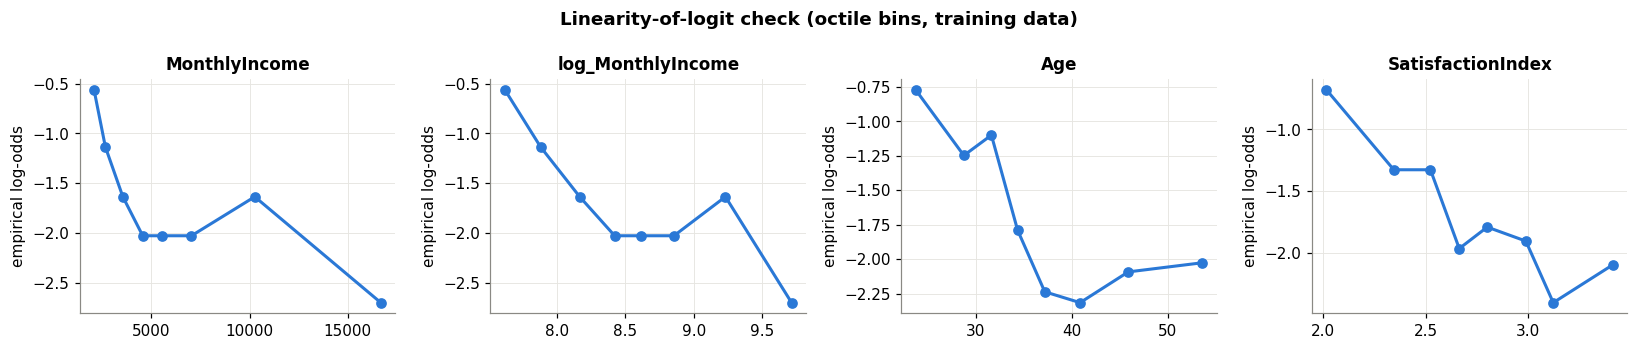

In [34]:
# Assumption check (iv): empirical log-odds of attrition across deciles should be roughly monotone/linear
def emp_logit(x, y, q=8):
    b = pd.qcut(x.rank(method="first"), q, labels=False)
    g = pd.DataFrame({"x": x, "y": y, "b": b}).groupby("b").agg(x=("x", "mean"), p=("y", "mean"))
    g["logit"] = np.log((g.p + .01) / (1 - g.p + .01)); return g
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, (c, src) in zip(axes, [("MonthlyIncome", X_train_raw), ("log_MonthlyIncome", Xtr_fe), ("Age", X_train_raw), ("SatisfactionIndex", Xtr_fe)]):
    g = emp_logit(src[c], y_train)
    ax.plot(g.x, g.logit, marker="o", ms=6, color=C_STAY, lw=2); ax.set_title(c); ax.set_ylabel("empirical log-odds")
fig.suptitle("Linearity-of-logit check (octile bins, training data)", fontweight="bold")
plt.tight_layout(); save(fig, "logit_linearity"); plt.show()

**Observations.** 
- Raw `MonthlyIncome` has a strongly curved log-odds: risk falls steeply over the first ~5,000 and then flattens. After `log1p` the relationship is closer to linear over most of the range, which supports the transform.
- `Age` shows a steep decline up to ~37 and then a plateau/slight rise. A single linear term only approximates this, which is a known limitation.
- `SatisfactionIndex` decreases almost monotonically, which suits a linear log-odds term.


### 8.2 Experimental design
All experiments use the **same training data, the same 5-fold stratified CV splits and the same seed**, and change **one thing at a time**, so the effect of each preprocessing / feature-engineering decision is isolated.

| ID | Experiment | What changes |
|---|---|---|
| E0 | Dummy (majority class) | Reference floor |
| E1 | Baseline LR | Raw features (constants/ID removed), one-hot + scaling, default C=1 |
| E1u | Baseline LR **without scaling** | Shows why scaling matters |
| E2 | + Engineered features | Adds 9 ratio/composite features + log transforms |
| E3 | + Feature selection | Drops noise, collinear, redundant and protected features (Section 7.2) |
| E3o | E3 with ordinals one-hot encoded | Tests the ordinal-as-integer decision |
| E4 | E3 + `class_weight='balanced'` | Re-weights the minority class during training |

In [35]:
def make_pipeline(engineer=True, log_transform=True, drop=(), scale=True, ordinal_onehot=False, class_weight=None, C=1.0, penalty="l2"):
    cat = [c for c in nominal_cols if c not in drop] + ([c for c in ordinal_cols if c not in drop] if ordinal_onehot else [])
    def num_selector(X):  # every non-categorical column that survives the drop list
        return [c for c in X.columns if c not in cat and c not in drop and c not in nominal_cols]
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat),
        ("num", StandardScaler() if scale else "passthrough", num_selector),
    ], remainder="drop", verbose_feature_names_out=False)
    steps = ([("fe", FeatureEngineer(log_transform=log_transform))] if engineer else []) + \
            [("pre", pre), ("clf", LogisticRegression(C=C, penalty=penalty, class_weight=class_weight,
                                                      solver="liblinear" if penalty == "l1" else "lbfgs", max_iter=5000 if scale else 200,
                                                      random_state=RANDOM_STATE))]
    return Pipeline(steps)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "recall": "recall", "precision": "precision", "f1": "f1", "accuracy": "accuracy"}
def evaluate_cv(name, model, X=X_train_raw):
    r = cross_validate(model, X, y_train, cv=cv, scoring=SCORING, n_jobs=1)
    row = {"experiment": name}
    for k in SCORING: row[k] = r["test_" + k].mean(); row[k + "_sd"] = r["test_" + k].std()
    return row

DROP_SEL = tuple(drop_noise + drop_collinear + drop_fairness + drop_redundant)
DROP_BASE = ("EmployeeNumber",)
experiments = {
    "E0 Dummy (majority)": Pipeline([("clf", DummyClassifier(strategy="prior"))]),
    "E1 Baseline LR (raw features)": make_pipeline(engineer=False),
    "E1u Baseline LR, no scaling": make_pipeline(engineer=False, scale=False),
    "E2 + engineered features": make_pipeline(engineer=True),
    "E3 + feature selection": make_pipeline(engineer=True, drop=DROP_SEL),
    "E3o E3 + one-hot ordinals": make_pipeline(engineer=True, drop=DROP_SEL, ordinal_onehot=True),
    "E4 E3 + class_weight=balanced": make_pipeline(engineer=True, drop=DROP_SEL, class_weight="balanced"),
}
results = pd.DataFrame([evaluate_cv(n, m) for n, m in experiments.items()]).set_index("experiment")
results[["roc_auc", "roc_auc_sd", "pr_auc", "recall", "precision", "f1", "accuracy"]].round(3)

,roc_auc,roc_auc_sd,pr_auc,recall,precision,f1,accuracy
experiment,,,,,,,
E0 Dummy (majority),0.500,0.000,0.162,0.000,0.000,0.000,0.838
E1 Baseline LR (raw features),0.838,0.030,0.652,0.442,0.793,0.565,0.891
"E1u Baseline LR, no scaling",0.735,0.053,0.392,0.058,0.427,0.100,0.836
E2 + engineered features,0.853,0.026,0.671,0.468,0.747,0.570,0.888
E3 + feature selection,0.854,0.023,0.681,0.474,0.771,0.582,0.892
E3o E3 + one-hot ordinals,0.853,0.029,0.686,0.458,0.759,0.563,0.888
E4 E3 + class_weight=balanced,0.849,0.021,0.651,0.758,0.412,0.531,0.783


Visual comparison of the experiments, and the number of model inputs each one uses:

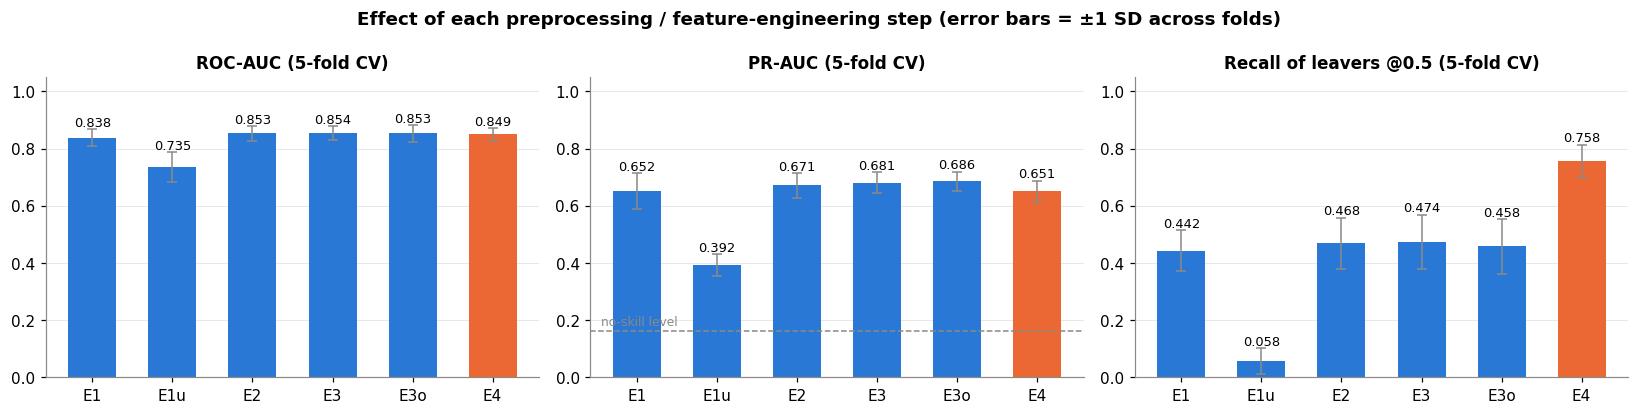

experiment,E0 Dummy (majority),E1 Baseline LR (raw features),"E1u Baseline LR, no scaling",E2 + engineered features,E3 + feature selection,E3o E3 + one-hot ordinals,E4 E3 + class_weight=balanced
n_model_inputs,NaN,44.0,44.0,53.0,41.0,56.0,41.0


In [36]:
# Number of model inputs after encoding, per experiment (model complexity)
n_inputs = {}
for n, m in experiments.items():
    if n.startswith("E0"): continue
    m.fit(X_train_raw, y_train); n_inputs[n] = m.named_steps["clf"].coef_.shape[1]
results["n_model_inputs"] = pd.Series(n_inputs)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
names = [n for n in results.index if not n.startswith("E0")]
short = [n.split(" ")[0] for n in names]
for ax, m, t in zip(axes, ["roc_auc", "pr_auc", "recall"], ["ROC-AUC (5-fold CV)", "PR-AUC (5-fold CV)", "Recall of leavers @0.5 (5-fold CV)"]):
    v, e = results.loc[names, m], results.loc[names, m + "_sd"]
    colors = [C_LEFT if s == "E4" else C_STAY for s in short]
    ax.bar(short, v, yerr=e, color=colors, width=.6, capsize=3, error_kw=dict(ecolor=C_NEUTRAL, lw=1))
    for i, x in enumerate(v): ax.text(i, x + e.iloc[i] + .01, f"{x:.3f}", ha="center", fontsize=8.5)
    ax.set_title(t); ax.set_ylim(0, 1.05); ax.grid(axis="x", visible=False)
    if m == "pr_auc": ax.axhline(y_train.mean(), color=C_NEUTRAL, ls="--", lw=1); ax.text(-.45, y_train.mean() + .02, "no-skill level", fontsize=8, ha="left", color=C_NEUTRAL)
fig.suptitle("Effect of each preprocessing / feature-engineering step (error bars = ±1 SD across folds)", fontweight="bold")
plt.tight_layout(); save(fig, "experiments"); plt.show()
results[["n_model_inputs"]].T

**Observations.** 
- **E0 → E1:** plain Logistic Regression already lifts ROC-AUC from 0.50 to **0.838** and PR-AUC from 0.16 (no-skill) to **0.652**.
- **Scaling matters (E1 vs E1u):** without standardisation ROC-AUC falls to 0.735 and recall to 0.06. The solver fails to converge within its iteration limit, and the penalty is applied unevenly across feature scales. This is a clear demonstration of why preprocessing matters for Logistic Regression.
- **Feature engineering helps (E1 → E2):** ROC-AUC 0.838 → **0.853** and PR-AUC 0.652 → 0.671, with lower fold-to-fold variability (SD 0.030 → 0.026).
- **Feature selection keeps performance while simplifying (E2 → E3):** PR-AUC rises slightly to **0.681** with 53 → 41 inputs and lower variance. The removed features were noise or redundant. E3 is also much easier to interpret because collinearity has been removed.
- **One-hot encoding the ordinals (E3o)** gives no meaningful gain (0.686 vs 0.681, well within one SD) at the cost of 15 extra inputs. Keeping ordinals as integers is justified.
- **Class weighting (E4)** does not improve ranking quality (ROC-AUC 0.849), but it moves the operating point: **recall jumps from 0.47 to 0.76** while precision falls from 0.77 to 0.41. It works like lowering the threshold. Because the threshold can be tuned explicitly (Section 10.1), this is treated as a threshold choice rather than a better model.
- Overall, the gains from feature engineering and selection are modest (+0.016 ROC-AUC) and similar in size to the fold SD. The honest conclusion is that the raw features already contain most of the linear signal, and the engineered features mainly add interpretability and stability.


## 9. Model Refinement — limited hyperparameter experimentation
*(Tuning is done on cross-validation before the final test-set evaluation, so the test set is used exactly once.)*

Logistic Regression has few hyperparameters; the ones that matter:
- **`C`** — inverse regularisation strength. Small C = strong penalty = simpler model (higher bias); large C = weak penalty (higher variance).
- **`penalty`** — L2 (shrinks all coefficients smoothly) vs L1 (can set coefficients to exactly 0 → built-in feature selection).
- **`class_weight`** — `None` vs `'balanced'` (up-weights leavers during training).

A small grid (7 × 2 × 2 = 28 configurations) is searched with the same 5-fold CV, scored on **PR-AUC** (average precision), which focuses on how well the minority class is ranked. Because many configurations score within noise of each other, the final choice uses the **one-standard-error rule**: the most strongly regularised configuration whose CV PR-AUC is within one standard error of the best one.

In [37]:
base = make_pipeline(engineer=True, drop=DROP_SEL)
grid = {"clf__C": [0.001, 0.01, 0.03, 0.1, 0.3, 1, 10], "clf__penalty": ["l1", "l2"], "clf__class_weight": [None, "balanced"], "clf__solver": ["liblinear"]}
def one_se_rule(cv_results):
    # Pick the MOST regularised model (smallest C) whose CV PR-AUC is within one standard error of the best.
    # Classic bias-variance safeguard (Hastie et al.): prefer the simpler model when the difference is within noise.
    r = pd.DataFrame(cv_results)
    best = r.mean_test_pr_auc.idxmax()
    se = r.loc[best, "std_test_pr_auc"] / np.sqrt(cv.get_n_splits())
    ok = r[r.mean_test_pr_auc >= r.loc[best, "mean_test_pr_auc"] - se]
    ok = ok.assign(C=ok.param_clf__C.astype(float), l1=(ok.param_clf__penalty == "l1").astype(int))
    return int(ok.sort_values(["C", "l1", "mean_test_pr_auc"], ascending=[True, False, False]).index[0])
gs = GridSearchCV(base, grid, scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc", "recall": "recall", "f1": "f1"},
                  refit=one_se_rule, cv=cv, n_jobs=1)
gs.fit(X_train_raw, y_train)
_best_raw = pd.DataFrame(gs.cv_results_).mean_test_pr_auc.idxmax()
print("Highest CV PR-AUC config:", gs.cv_results_["params"][_best_raw], round(gs.cv_results_["mean_test_pr_auc"][_best_raw], 4))
cvres = pd.DataFrame(gs.cv_results_)
cvres["class_weight"] = cvres.param_clf__class_weight.map(lambda v: "balanced" if v == "balanced" else "None")
tbl = cvres[["param_clf__C", "param_clf__penalty", "class_weight", "mean_test_pr_auc", "std_test_pr_auc", "mean_test_roc_auc", "mean_test_recall", "mean_test_f1"]]
print("Selected by 1-SE rule :", gs.best_params_, "| CV PR-AUC:", round(gs.cv_results_["mean_test_pr_auc"][gs.best_index_], 4))
tbl.sort_values("mean_test_pr_auc", ascending=False).head(10).round(4)

Highest CV PR-AUC config: {'clf__C': 10, 'clf__class_weight': None, 'clf__penalty': 'l2', 'clf__solver': 'liblinear'} 0.6841
Selected by 1-SE rule : {'clf__C': 0.1, 'clf__class_weight': None, 'clf__penalty': 'l2', 'clf__solver': 'liblinear'} | CV PR-AUC: 0.6714


,param_clf__C,param_clf__penalty,class_weight,mean_test_pr_auc,std_test_pr_auc,mean_test_roc_auc,mean_test_recall,mean_test_f1
25,10.0,l2,None,0.6841,0.0385,0.8568,0.4895,0.5884
20,1.0,l1,None,0.6841,0.0353,0.8549,0.4579,0.5742
21,1.0,l2,None,0.6829,0.0424,0.8526,0.4789,0.5889
24,10.0,l1,None,0.6821,0.0431,0.8564,0.4895,0.5884
17,0.3,l2,None,0.6818,0.0510,0.8489,0.4368,0.5534
16,0.3,l1,None,0.6773,0.0442,0.8494,0.4158,0.5370
13,0.1,l2,None,0.6714,0.0684,0.8425,0.3842,0.5099
19,0.3,l2,balanced,0.6550,0.0440,0.8486,0.7632,0.5356
15,0.1,l2,balanced,0.6538,0.0480,0.8455,0.7579,0.5302
22,1.0,l1,balanced,0.6529,0.0386,0.8488,0.7579,0.5323


**How each hyperparameter changes model behaviour** across the grid:

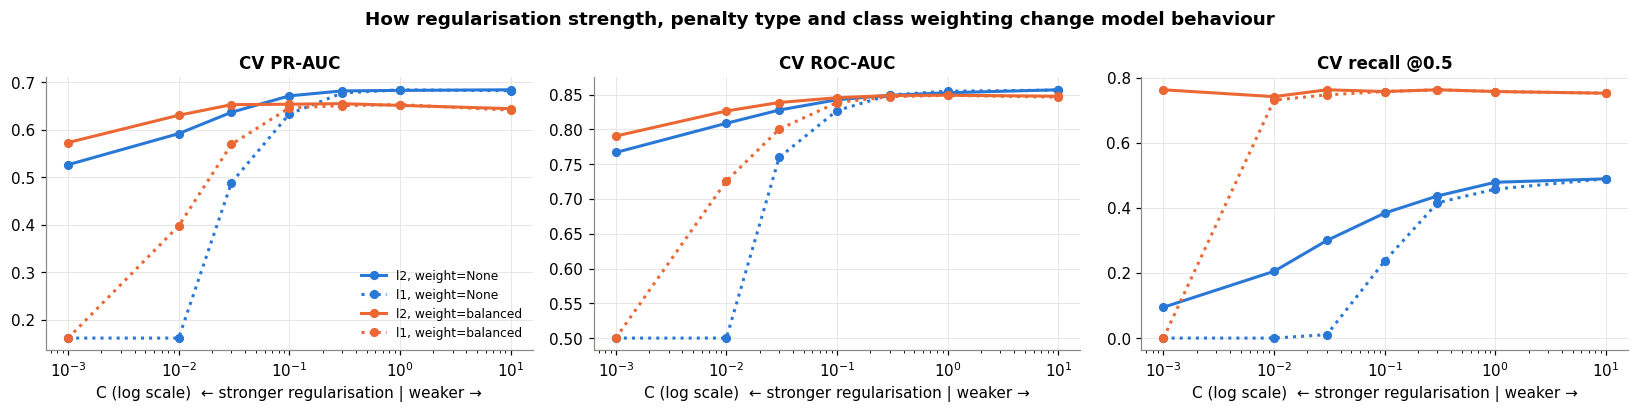

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
styles = {("l2", "None"): (C_STAY, "-"), ("l1", "None"): (C_STAY, ":"), ("l2", "balanced"): (C_LEFT, "-"), ("l1", "balanced"): (C_LEFT, ":")}
for ax, m, t in zip(axes, ["mean_test_pr_auc", "mean_test_roc_auc", "mean_test_recall"], ["CV PR-AUC", "CV ROC-AUC", "CV recall @0.5"]):
    for (pen, cw), (colr, ls) in styles.items():
        d = cvres[(cvres.param_clf__penalty == pen) & (cvres.class_weight == cw)].sort_values("param_clf__C")
        ax.plot(d.param_clf__C.astype(float), d[m], color=colr, ls=ls, lw=2, marker="o", ms=5, label=f"{pen}, weight={cw}")
    ax.set_xscale("log"); ax.set_xlabel("C (log scale)  ← stronger regularisation | weaker →"); ax.set_title(t)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("How regularisation strength, penalty type and class weighting change model behaviour", fontweight="bold")
plt.tight_layout(); save(fig, "tuning_curves"); plt.show()

With the L1 penalty, smaller C forces more coefficients to exactly zero (built-in feature selection):

In [39]:
# Effect of C on model sparsity (L1): how many coefficients survive?
sp = []
for C in [0.01, 0.03, 0.1, 0.3, 1, 10]:
    m = make_pipeline(engineer=True, drop=DROP_SEL, C=C, penalty="l1", class_weight="balanced").fit(X_train_raw, y_train)
    sp.append((C, int((np.abs(m.named_steps["clf"].coef_) > 1e-6).sum()), m.named_steps["clf"].coef_.shape[1]))
pd.DataFrame(sp, columns=["C", "non_zero_coefficients", "total_inputs"]).set_index("C")

,non_zero_coefficients,total_inputs
C,,
0.01,6,41
0.03,13,41
0.10,24,41
0.30,31,41
1.00,36,41
10.00,40,41


**Learning curve** — does the model suffer from high bias or high variance, and would more data help?

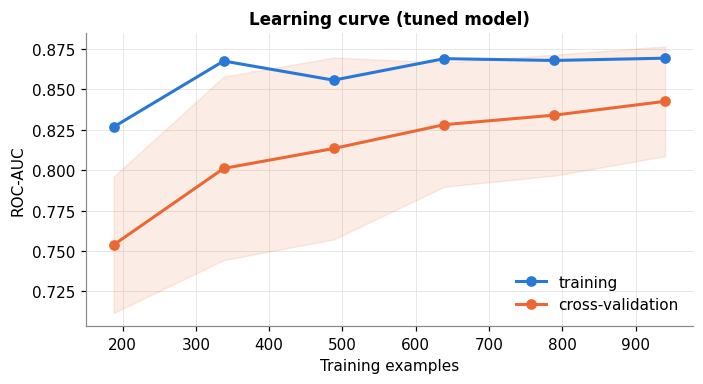

In [40]:
# Learning curve of the tuned model: is more data likely to help? (bias vs variance)
final_model = gs.best_estimator_
sizes, tr_sc, va_sc = learning_curve(final_model, X_train_raw, y_train, cv=cv, scoring="roc_auc", train_sizes=np.linspace(.2, 1, 6), n_jobs=1)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(sizes, tr_sc.mean(1), marker="o", color=C_STAY, lw=2, label="training")
ax.plot(sizes, va_sc.mean(1), marker="o", color=C_LEFT, lw=2, label="cross-validation")
ax.fill_between(sizes, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), color=C_LEFT, alpha=.12)
ax.set_xlabel("Training examples"); ax.set_ylabel("ROC-AUC"); ax.legend(frameon=False); ax.set_title("Learning curve (tuned model)")
plt.tight_layout(); save(fig, "learning_curve"); plt.show()

**Observations.** 
- **Too much regularisation hurts:** at C ≤ 0.01, L1 zeroes out almost every coefficient (6 of 41 survive at C = 0.01) and performance collapses to near chance. Performance plateaus from **C ≈ 0.1 to 10**, so the model is not sensitive to C within that range.
- The top configurations are separated by less than 0.015 PR-AUC, below the fold SD (≈ 0.04). Choosing the "max" would be chasing noise. The **one-standard-error rule** therefore selects **C = 0.1, L2, no class weight** (CV PR-AUC 0.671, ROC-AUC 0.843), the most regularised model that is statistically indistinguishable from the best. Its advantage is **stability**: in the bootstrap (Section 10.2) every major coefficient keeps the same sign in 99.5–100% of resamples.
- **Class weighting** consistently lowers PR-AUC slightly but lifts recall to ~0.76 at the 0.5 threshold. It is a threshold shift, not better ranking.
- **L1 vs L2** perform the same at C ≥ 0.3. L2 is preferred at C = 0.1 because L1 starts dropping useful correlated features there.
- The **learning curve** shows training AUC flat at ~0.87 while cross-validation AUC is **still rising** at the full training size (0.75 at 190 rows → 0.84 at 940 rows). The gap has narrowed to ~0.03, so there is little overfitting, and **more data would still help modestly**. The training ceiling of ~0.87 marks the limit of what a linear model can do with these features.


## 10. Model Evaluation & Interpretation (held-out test set)
The tuned pipeline is refitted on the full training set (done by `GridSearchCV`) and evaluated **once** on the untouched 20% test set. The baseline E1 is evaluated alongside for comparison.

In [41]:
baseline = make_pipeline(engineer=False).fit(X_train_raw, y_train)
def test_metrics(model, X, y, thr=0.5):
    p = model.predict_proba(X)[:, 1]; yhat = (p >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p), "Recall": recall_score(y, yhat),
            "Precision": precision_score(y, yhat, zero_division=0), "F1": f1_score(y, yhat), "Accuracy": accuracy_score(y, yhat),
            "Brier": brier_score_loss(y, p), "Flagged %": yhat.mean()}
p_test = final_model.predict_proba(X_test_raw)[:, 1]
test_tbl = pd.DataFrame({"E1 baseline @0.5": test_metrics(baseline, X_test_raw, y_test),
                         "Tuned model @0.5": test_metrics(final_model, X_test_raw, y_test)}).T
test_tbl.round(3)

,ROC-AUC,PR-AUC,Recall,Precision,F1,Accuracy,Brier,Flagged %
E1 baseline @0.5,0.81,0.593,0.340,0.640,0.444,0.864,0.098,0.085
Tuned model @0.5,0.79,0.546,0.319,0.682,0.435,0.867,0.104,0.075


**How reliable are these test numbers?** Bootstrapping the test set gives confidence intervals:

In [42]:
# How much of the test-set difference is just sampling noise? Bootstrap the 294 test employees 1,000 times.
rng = np.random.default_rng(RANDOM_STATE)
p_base = baseline.predict_proba(X_test_raw)[:, 1]; yt = y_test.values; bs = []
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    if yt[i].sum() == 0: continue
    bs.append((roc_auc_score(yt[i], p_test[i]), roc_auc_score(yt[i], p_base[i]),
               average_precision_score(yt[i], p_test[i]), average_precision_score(yt[i], p_base[i])))
bs = pd.DataFrame(bs, columns=["auc_tuned", "auc_base", "ap_tuned", "ap_base"])
bs["auc_diff"] = bs.auc_tuned - bs.auc_base; bs["ap_diff"] = bs.ap_tuned - bs.ap_base
bs.quantile([.025, .5, .975]).T.rename(columns={.025: "2.5%", .5: "median", .975: "97.5%"}).round(3)

,2.5%,median,97.5%
auc_tuned,0.709,0.791,0.864
auc_base,0.731,0.812,0.883
ap_tuned,0.408,0.552,0.681
ap_base,0.446,0.596,0.715
auc_diff,-0.063,-0.021,0.015
ap_diff,-0.133,-0.044,0.047


ROC and precision-recall curves (threshold-free) and the calibration of the predicted probabilities:

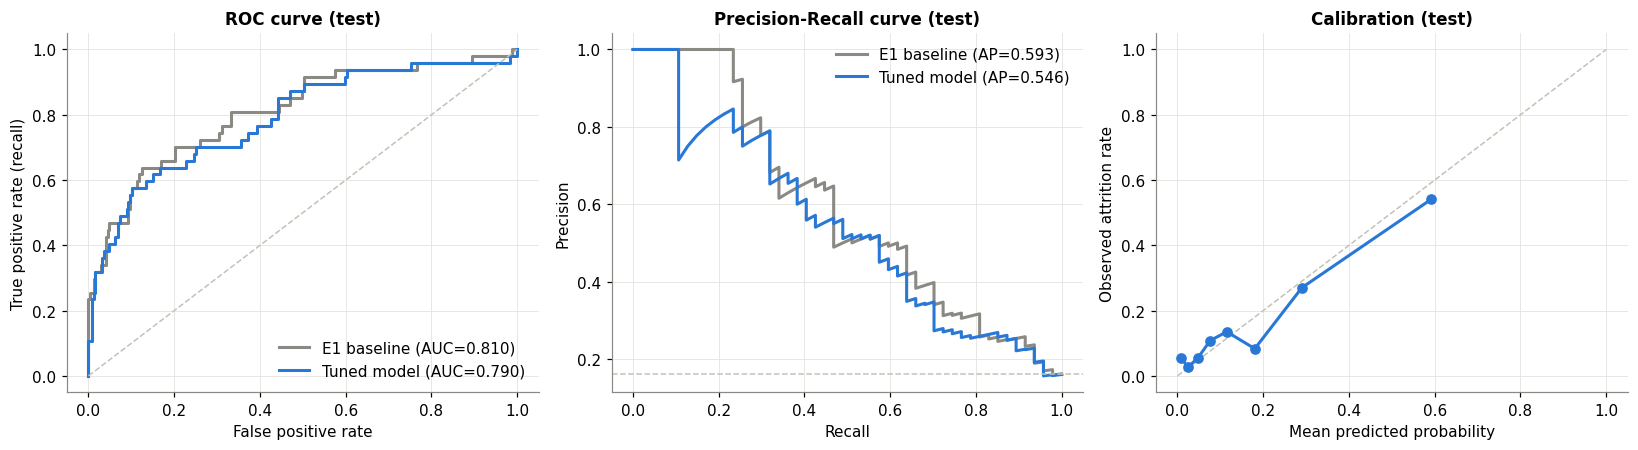

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
# ROC
for m, name, colr in [(baseline, "E1 baseline", C_NEUTRAL), (final_model, "Tuned model", C_STAY)]:
    pp = m.predict_proba(X_test_raw)[:, 1]; fpr, tpr, _ = roc_curve(y_test, pp)
    axes[0].plot(fpr, tpr, color=colr, lw=2, label=f"{name} (AUC={roc_auc_score(y_test, pp):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, pp)
    axes[1].plot(rc, pr, color=colr, lw=2, label=f"{name} (AP={average_precision_score(y_test, pp):.3f})")
axes[0].plot([0, 1], [0, 1], ls="--", color="#c3c2b7", lw=1); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curve (test)"); axes[0].legend(frameon=False, loc="lower right")
axes[1].axhline(y_test.mean(), ls="--", color="#c3c2b7", lw=1); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curve (test)"); axes[1].legend(frameon=False)
# Calibration
fr, mp = calibration_curve(y_test, p_test, n_bins=8, strategy="quantile")
axes[2].plot([0, 1], [0, 1], ls="--", color="#c3c2b7", lw=1); axes[2].plot(mp, fr, marker="o", color=C_STAY, lw=2)
axes[2].set_xlabel("Mean predicted probability"); axes[2].set_ylabel("Observed attrition rate"); axes[2].set_title("Calibration (test)")
plt.tight_layout(); save(fig, "roc_pr_calibration"); plt.show()

**Observations.** 
- On the untouched test set (294 employees, 47 leavers) the tuned model reaches **ROC-AUC 0.790** and **PR-AUC 0.546**, about 3.4× the 0.16 no-skill level. This is a little below its CV estimate (0.843 / 0.671), as expected for a single small test set.
- The **E1 baseline scores slightly higher on this particular test set** (0.810 / 0.593). The bootstrap shows this difference is **not meaningful**: the 95% interval for the AUC difference is [−0.063, +0.015] and includes zero. Each model's AUC interval is about ±0.08 wide, because a test set with 47 positives cannot resolve differences of 0.02. On the more reliable 5-fold CV the engineered models were slightly better. **Conclusion: the two models perform statistically the same.** The tuned model is preferred for its lower collinearity, stable coefficients and interpretable features, not for a higher score.
- **Calibration** is reasonable up to ~0.3. Above that the model slightly **over-predicts** risk (predicted ~0.59 vs observed ~0.54 in the top bin). The probabilities can be used as a ranking and as rough risk levels.


### 10.1 Choosing a decision threshold
The default 0.5 threshold is arbitrary. The business trade-off is: **missing a leaver** (false negative) costs replacement — commonly estimated at several months of salary — while **over-flagging a stayer** (false positive) costs a retention conversation or review that turns out to be unnecessary. We use an *illustrative* cost ratio of **FN : FP = 5 : 1** and pick the threshold that minimises expected cost **on out-of-fold training predictions** (not on the test set), then apply it to the test set.

Cost-optimal threshold (FN:FP = 5:1) = 0.29 | F1-optimal threshold = 0.32


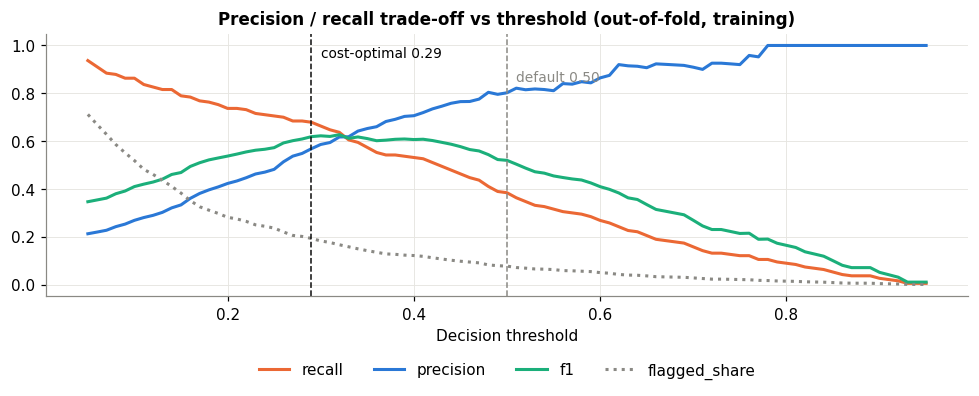

,recall,precision,f1,flagged_share,cost
threshold,,,,,
0.20,0.737,0.423,0.537,0.281,441
0.30,0.663,0.586,0.622,0.183,409
0.40,0.532,0.706,0.607,0.122,487
0.50,0.384,0.802,0.520,0.077,603
0.60,0.268,0.864,0.410,0.050,703
0.70,0.158,0.909,0.269,0.028,803
0.29,0.679,0.568,0.619,0.193,403


In [44]:
from sklearn.model_selection import cross_val_predict
oof = cross_val_predict(final_model, X_train_raw, y_train, cv=cv, method="predict_proba")[:, 1]
COST_FN, COST_FP = 5, 1
ths = np.round(np.arange(0.05, 0.951, 0.01), 2)
rows = []
for t in ths:
    yh = (oof >= t).astype(int); tn, fp, fn, tp = confusion_matrix(y_train, yh).ravel()
    rows.append((t, recall_score(y_train, yh), precision_score(y_train, yh, zero_division=0), f1_score(y_train, yh), yh.mean(), COST_FN * fn + COST_FP * fp))
thr_df = pd.DataFrame(rows, columns=["threshold", "recall", "precision", "f1", "flagged_share", "cost"]).set_index("threshold")
t_cost = thr_df.cost.idxmin(); t_f1 = thr_df.f1.idxmax()
print(f"Cost-optimal threshold (FN:FP = {COST_FN}:{COST_FP}) = {t_cost:.2f} | F1-optimal threshold = {t_f1:.2f}")
fig, ax = plt.subplots(figsize=(9, 3.8))
for c, colr, ls in [("recall", C_LEFT, "-"), ("precision", C_STAY, "-"), ("f1", "#1baf7a", "-"), ("flagged_share", C_NEUTRAL, ":")]:
    ax.plot(thr_df.index, thr_df[c], color=colr, ls=ls, lw=2, label=c)
ax.axvline(t_cost, color="#0b0b0b", lw=1, ls="--"); ax.text(t_cost + .01, .95, f"cost-optimal {t_cost:.2f}", fontsize=9)
ax.axvline(.5, color=C_NEUTRAL, lw=1, ls="--"); ax.text(.51, .85, "default 0.50", fontsize=9, color=C_NEUTRAL)
ax.set_xlabel("Decision threshold"); ax.set_title("Precision / recall trade-off vs threshold (out-of-fold, training)"); ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(.5, -.2))
plt.tight_layout(); save(fig, "threshold_tradeoff"); plt.show()
thr_df.loc[[t for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7] if t in thr_df.index] + [t_cost]].round(3)

Confusion matrices at the default and the cost-optimal threshold, with the full classification report:

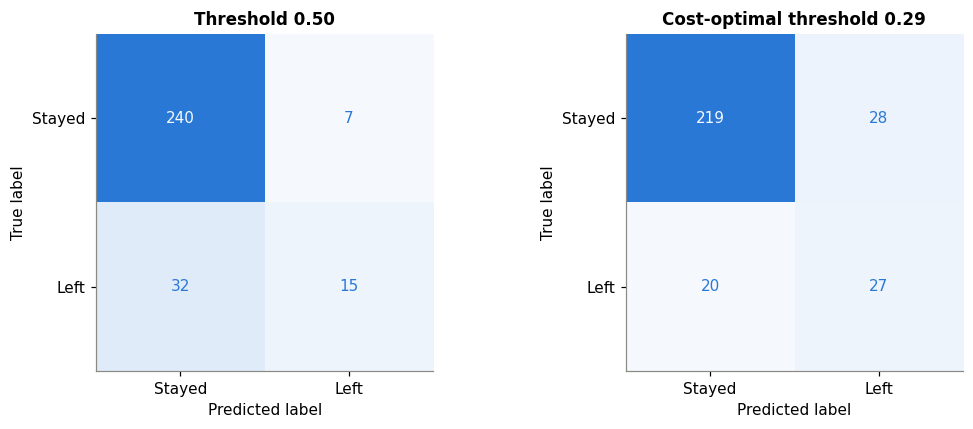

              precision    recall  f1-score   support

      Stayed      0.916     0.887     0.901       247
        Left      0.491     0.574     0.529        47

    accuracy                          0.837       294
   macro avg      0.704     0.731     0.715       294
weighted avg      0.848     0.837     0.842       294



,ROC-AUC,PR-AUC,Recall,Precision,F1,Accuracy,Brier,Flagged %
Threshold 0.50,0.79,0.546,0.319,0.682,0.435,0.867,0.104,0.075
Cost-optimal threshold 0.29,0.79,0.546,0.574,0.491,0.529,0.837,0.104,0.187


In [45]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
summary = {}
for ax, t, name in [(axes[0], .5, "Threshold 0.50"), (axes[1], t_cost, f"Cost-optimal threshold {t_cost:.2f}")]:
    yh = (p_test >= t).astype(int); cm = confusion_matrix(y_test, yh)
    ConfusionMatrixDisplay(cm, display_labels=["Stayed", "Left"]).plot(ax=ax, cmap=LinearSegmentedColormap.from_list("b", ["#f5f9fe", "#2a78d6"]), colorbar=False)
    ax.set_title(name); ax.grid(False)
    summary[name] = test_metrics(final_model, X_test_raw, y_test, t)
plt.tight_layout(); save(fig, "confusion_matrices"); plt.show()
print(classification_report(y_test, (p_test >= t_cost).astype(int), target_names=["Stayed", "Left"], digits=3))
pd.DataFrame(summary).T.round(3)

**Observations.** 
- With the default threshold of 0.5 the model catches only **32% of leavers** (15 of 47). That is too conservative for a retention use case.
- Using an illustrative cost ratio (a missed leaver costs 5× an unnecessary retention conversation), the cost-minimising threshold on out-of-fold training predictions is **0.29**. On the test set this gives **recall 0.57 (27 of 47 leavers caught)** and **precision 0.49**: about 1 in 2 flagged employees actually leaves, vs 1 in 6 at random. Only 18.7% of staff are flagged.
- **Trade-off:** lowering the threshold to 0.20 would catch ~74% of leavers (on CV) but flag 28% of the workforce. HR should set the threshold according to how many retention conversations it can afford. The threshold table shows this menu explicitly.
- Accuracy falls from 0.867 to 0.837 at the lower threshold. That is the expected and acceptable cost of catching more leavers.


### 10.2 What drives attrition? Coefficients as odds ratios

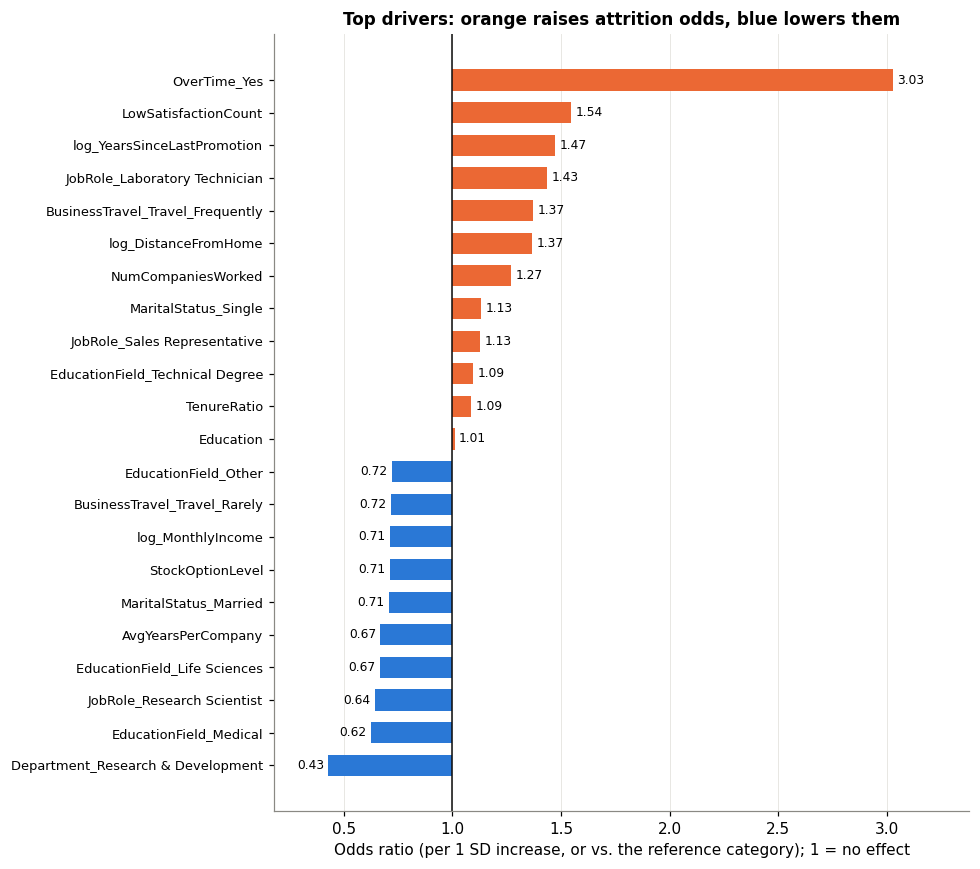

Intercept: -1.2 | non-zero coefficients: 41 of 41


,feature,coef,odds_ratio
19,OverTime_Yes,1.108,3.028
2,Department_Research & Development,-0.847,0.429
6,EducationField_Medical,-0.472,0.624
14,JobRole_Research Scientist,-0.443,0.642
36,LowSatisfactionCount,0.435,1.545
4,EducationField_Life Sciences,-0.407,0.665
32,AvgYearsPerCompany,-0.403,0.668
39,log_YearsSinceLastPromotion,0.386,1.471
10,JobRole_Laboratory Technician,0.361,1.434
17,MaritalStatus_Married,-0.344,0.709


In [46]:
clf = final_model.named_steps["clf"]; feat_names = final_model.named_steps["pre"].get_feature_names_out()
coef = pd.DataFrame({"feature": feat_names, "coef": clf.coef_[0]}); coef["odds_ratio"] = np.exp(coef.coef)
coef = coef[coef.coef.abs() > 1e-6].sort_values("coef")
top = pd.concat([coef.head(10), coef.tail(12)]).drop_duplicates()
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top.feature, top.odds_ratio - 1, left=1, color=[C_LEFT if v > 0 else C_STAY for v in top.coef], height=.65)
ax.axvline(1, color="#0b0b0b", lw=1)
for i, (orr, f) in enumerate(zip(top.odds_ratio, top.feature)):
    ax.text(orr + (.02 if orr >= 1 else -.02), i, f"{orr:.2f}", va="center", ha="left" if orr >= 1 else "right", fontsize=8)
lo, hi = top.odds_ratio.min(), top.odds_ratio.max(); ax.set_xlim(min(lo, 1) - .25, max(hi, 1) + .35)
ax.set_xlabel("Odds ratio (per 1 SD increase, or vs. the reference category); 1 = no effect")
ax.set_title("Top drivers: orange raises attrition odds, blue lowers them"); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8.5)
plt.tight_layout(); save(fig, "odds_ratios"); plt.show()
print("Intercept:", round(clf.intercept_[0], 3), "| non-zero coefficients:", len(coef), "of", len(feat_names))
coef.assign(abs_coef=coef.coef.abs()).sort_values("abs_coef", ascending=False).drop(columns="abs_coef").head(15).round(3)

**Are these drivers robust?** Refit the model on 200 bootstrap samples and check whether each coefficient keeps its sign:

In [47]:
# Robustness of the drivers: bootstrap the training set 200x and record coefficient sign stability
from sklearn.base import clone
rng = np.random.default_rng(RANDOM_STATE); boot = []
for _ in range(200):
    idx = rng.integers(0, len(X_train_raw), len(X_train_raw))
    m = clone(final_model)                     # identical configuration (incl. solver) to the selected model
    m.fit(X_train_raw.iloc[idx], y_train.iloc[idx])
    boot.append(pd.Series(m.named_steps["clf"].coef_[0], index=m.named_steps["pre"].get_feature_names_out()))
boot = pd.DataFrame(boot)
stab = pd.DataFrame({"mean_coef": boot.mean(), "ci_2.5%": boot.quantile(.025), "ci_97.5%": boot.quantile(.975),
                     "same_sign_%": (np.sign(boot) == np.sign(boot.mean())).mean() * 100})
stab.reindex(stab.mean_coef.abs().sort_values(ascending=False).index).head(15).round(3)

,mean_coef,ci_2.5%,ci_97.5%,same_sign_%
OverTime_Yes,1.104,0.855,1.345,100.0
Department_Research & Development,-0.853,-1.001,-0.702,100.0
EducationField_Medical,-0.460,-0.710,-0.232,100.0
JobRole_Research Scientist,-0.442,-0.654,-0.195,100.0
LowSatisfactionCount,0.440,0.245,0.643,100.0
EducationField_Life Sciences,-0.416,-0.618,-0.196,100.0
AvgYearsPerCompany,-0.412,-0.684,-0.208,100.0
log_YearsSinceLastPromotion,0.390,0.187,0.596,100.0
BusinessTravel_Travel_Rarely,-0.352,-0.560,-0.117,100.0
JobRole_Laboratory Technician,0.345,0.149,0.568,100.0


**Observations.** 
Odds ratios are per 1 standard deviation for numeric features, and vs. the reference category for one-hot features (reference levels: Non-Travel, Human Resources dept., HR education field, Healthcare Representative role, Divorced, OverTime = No). Coefficients are *adjusted* for all other features, so they can differ from the raw EDA rates. For example, Sales Representatives have the highest raw attrition (39.8%), but their adjusted odds ratio is only 1.13, because their low income, junior level and young age already explain most of that risk.
- **OverTime = Yes: odds × 3.0**. This is by far the strongest and most stable driver (bootstrap 95% CI for the coefficient 0.86–1.35, which excludes 0).
- **Risk-raising:** more low-satisfaction scores (× 1.54 per SD), more years since last promotion (× 1.47), Laboratory Technician role (× 1.43), frequent travel (× 1.37), longer commute (× 1.37), more previous employers (× 1.27), being single (× 1.13).
- **Protective:** R&D department (× 0.43 vs HR), longer average stay per employer (× 0.67), higher income (× 0.71), stock options (× 0.71), married vs divorced (× 0.71), older age.
- **Stability:** the 15 largest coefficients (24 of 41 overall) keep the same sign in ≥ 99.5% of 200 bootstrap refits, so the main drivers are robust rather than artefacts of one sample. Weaker effects are less certain, e.g. MaritalStatus = Single (83.5%) and Sales Representative (87%).
- **Caution:** these are **associations, not causes**. Overtime may be a symptom of under-staffing or disengagement rather than a cause of attrition.


### 10.3 Risk tiers and segment-level behaviour

In [48]:
test_view = X_test_raw.copy(); test_view["y"] = y_test.values; test_view["p"] = p_test
test_view["risk_tier"] = pd.cut(test_view.p, [0, .15, t_cost, 1], labels=["Low (<0.15)", f"Medium (0.15-{t_cost:.2f})", f"High (>={t_cost:.2f})"], include_lowest=True)
tiers = test_view.groupby("risk_tier", observed=True).agg(employees=("y", "size"), leavers=("y", "sum"), actual_attrition_rate=("y", "mean"), mean_predicted=("p", "mean"))
tiers["share_of_all_leavers"] = tiers.leavers / tiers.leavers.sum()
display(tiers.round(3))
dept_perf = []
for d, g in test_view.groupby("Department", observed=True):
    yh = (g.p >= t_cost).astype(int)
    dept_perf.append({"Department": d, "n": len(g), "leavers": int(g.y.sum()), "actual_rate": g.y.mean(), "mean_pred": g.p.mean(),
                      "recall": recall_score(g.y, yh, zero_division=0) if g.y.sum() else np.nan,
                      "ROC-AUC": roc_auc_score(g.y, g.p) if g.y.nunique() == 2 else np.nan})
pd.DataFrame(dept_perf).set_index("Department").round(3)

,employees,leavers,actual_attrition_rate,mean_predicted,share_of_all_leavers
risk_tier,,,,,
Low (<0.15),188,14,0.074,0.056,0.298
Medium (0.15-0.29),51,6,0.118,0.212,0.128
High (>=0.29),55,27,0.491,0.503,0.574


,n,leavers,actual_rate,mean_pred,recall,ROC-AUC
Department,,,,,,
Human Resources,15,2,0.133,0.161,0.500,0.808
Research & Development,197,29,0.147,0.133,0.414,0.737
Sales,82,16,0.195,0.249,0.875,0.890


**Observations.** 
- **Risk tiers work:** the **High** tier (p ≥ 0.29) contains 18.7% of test employees but **57% of all leavers**, with 49% actual attrition. The **Low** tier (64% of staff) has only 7.4% attrition. HR can focus effort on roughly one fifth of the workforce and reach more than half of future leavers.
- **By department:** the model works best in **Sales** (ROC-AUC 0.89, recall 0.875). It is weaker in **R&D** (0.74, recall 0.41), where leavers are harder to distinguish. HR has only 2 test leavers, too few to judge. This confirms that drivers differ by department: R&D attrition is less explained by the available features.


### 10.4 Fairness audit
`Gender` was excluded from the model, but other features could act as proxies. We compare error rates across groups on the test set at the chosen threshold. Large gaps in recall (who gets *helped*) or false-positive rate (who gets *wrongly flagged*) would be a warning sign. Age and MaritalStatus are used as predictors, so their gaps are examined too and discussed as a policy question.

In [49]:
test_view["AgeBand"] = pd.cut(test_view.Age, [17, 29, 39, 49, 61], labels=["18-29", "30-39", "40-49", "50+"])
fair = []
for col in ["Gender", "AgeBand", "MaritalStatus"]:
    for grp, g in test_view.groupby(col, observed=True):
        yh = (g.p >= t_cost).astype(int); tn, fp, fn, tp = confusion_matrix(g.y, yh, labels=[0, 1]).ravel()
        fair.append({"attribute": col, "group": grp, "n": len(g), "actual_rate": g.y.mean(), "flag_rate": yh.mean(),
                     "recall(TPR)": tp / (tp + fn) if tp + fn else np.nan, "FPR": fp / (fp + tn) if fp + tn else np.nan})
pd.DataFrame(fair).set_index(["attribute", "group"]).round(3)

n  actual_rate  flag_rate  recall(TPR)    FPR
attribute     group                                                    
Gender        Female    116        0.138      0.181        0.625  0.110
              Male      178        0.174      0.191        0.548  0.116
AgeBand       18-29      68        0.250      0.338        0.647  0.235
              30-39     125        0.112      0.176        0.786  0.099
              40-49      67        0.119      0.119        0.375  0.085
              50+        34        0.235      0.059        0.250  0.000
MaritalStatus Divorced   64        0.062      0.109        0.500  0.083
              Married   133        0.135      0.105        0.389  0.061
              Single     97        0.258      0.351        0.720  0.222

**Sensitivity check** — performance without the demographic features Age and MaritalStatus:

In [50]:
# Sensitivity: what does the model lose if MaritalStatus and Age (demographic features) are also removed?
m_nodemo = make_pipeline(engineer=True, drop=DROP_SEL + ("MaritalStatus", "Age")).set_params(**gs.best_params_)
pd.DataFrame([evaluate_cv("Tuned model", final_model), evaluate_cv("Tuned model without Age & MaritalStatus", m_nodemo)]).set_index("experiment")[["roc_auc", "pr_auc", "recall", "precision", "f1"]].round(3)

,roc_auc,pr_auc,recall,precision,f1
experiment,,,,,
Tuned model,0.843,0.671,0.384,0.802,0.510
Tuned model without Age & MaritalStatus,0.840,0.648,0.368,0.803,0.501


**Observations.** 
- **Gender (excluded from the model):** recall is similar (62.5% F vs 54.8% M) and false-positive rates are almost equal (11.0% vs 11.6%). There is no evidence that the model acts as a gender proxy.
- **Age:** employees **under 30** are flagged most often (FPR 23.5%). This mirrors their genuinely higher attrition (25%). **Employees aged 50+** have recall of only 25% (2 of 8 leavers; n = 34, very small). Their attrition is probably driven by retirement, which the features cannot capture.
- **Marital status:** single employees have a higher FPR (22%), again reflecting a higher base rate.
- **Sensitivity:** removing Age and MaritalStatus costs little (CV ROC-AUC 0.843 → 0.840, PR-AUC 0.671 → 0.648). If HR policy forbids demographic inputs, a demographic-free model is a viable alternative with almost the same performance. This is recommended for deployment-style use.


## 11. Key Findings & Discussion

**Answers to the business questions**

1. **Which factors most strongly predict attrition?** **Overtime** (odds × 3.0) is dominant. It is followed by **job-hopping history** (short average stay per employer), **dissatisfaction** (number of survey scores at the lowest level), **years since last promotion**, **frequent business travel**, **long commute**, **low income / no stock options**, **entry-level roles** (Sales Representative, Laboratory Technician) and being **young / single**. Longer-tenured, senior, better-paid R&D staff rarely leave.
2. **How early can at-risk employees be flagged?** The dataset is a single snapshot with no dates, so lead time cannot be measured. What the data does show is that risk is highest in the **first two years** (35% attrition in year 0–1), so onboarding-stage monitoring is where the model adds most value. Measuring true lead time would require time-stamped HR records.
3. **What trade-off between catching leavers and over-flagging?** At the cost-optimal threshold (0.29) the model catches **57% of leavers while flagging 19% of staff**, with **~49% precision**, vs 16% if HR picked people at random. The threshold table gives HR a menu of options: 0.20 for ~74% recall with 28% flagged, or 0.40 for ~53% recall with 12% flagged.
4. **Do drivers differ across departments/roles?** The same main drivers (overtime, entry level, low satisfaction) raise risk in all departments, but their intensity differs. Sales is the most sensitive: 42% attrition at JobLevel 1 and 37.5% with overtime. The model is also most accurate in Sales (AUC 0.89) and least accurate in R&D (0.74).

**Impact of preprocessing and feature-engineering decisions**
- **Scaling** was the single most important preprocessing step: +0.10 ROC-AUC and +0.26 PR-AUC vs no scaling.
- **Log transforms** straightened the income–risk relationship.
- **Engineered features** added modest performance (+0.016 AUC) but produced the strongest single predictor (`AvgYearsPerCompany`) and composite satisfaction signals that were stronger than any individual score.
- **Feature selection / VIF treatment** removed 12 features with no loss of performance and made the coefficients stable enough to interpret.

**Model behaviour and limitations**
- Logistic Regression is **interpretable and well-calibrated at low risk**, and **stable** under resampling. As a linear model it cannot capture non-linear effects (e.g. age) or interactions (e.g. single × overtime) unless they are engineered explicitly.
- Small test set (47 leavers): test metrics have ±0.08 uncertainty, so CV estimates are more reliable.
- **Synthetic IBM data**: patterns are plausible but may not transfer to a real organisation. The model would need retraining on local data.
- No time dimension, so lead time and the causal direction cannot be established.
- **Future improvements:** explicit interaction terms (OverTime × MaritalStatus, JobLevel × Department), spline/binned age, time-stamped data for survival-style analysis, and (in later trimesters) non-linear models for comparison.

**Recommended HR actions**
- Review **overtime** allocation, especially for single, entry-level Sales and Laboratory staff.
- Put structured check-ins in place in the **first two years**.
- Follow up quickly when any engagement score hits **1 (Low)**.
- Review **promotion cadence** and **stock-option eligibility** for junior staff.
- Consider **travel load** for frequent travellers.

## 12. Conclusion

This project built an end-to-end, reproducible Logistic Regression pipeline to predict employee attrition on the IBM HR dataset (1,470 employees, 16.1% attrition).

Careful preprocessing mattered: dropping constants and the ID, keeping genuine outliers but log-transforming them, and standardising. Standardisation alone lifted PR-AUC from 0.39 to 0.65. Feature engineering produced interpretable features, including the strongest single predictor, `AvgYearsPerCompany`. VIF-guided feature selection cut 39 candidate features to 27 with a maximum VIF of 9.6 and no loss of accuracy.

The final model (L2, C = 0.1, chosen by the one-standard-error rule) achieves **cross-validated ROC-AUC 0.84 / PR-AUC 0.67**, and **ROC-AUC 0.79 / PR-AUC 0.55 on the held-out test set**. That is statistically on a par with the baseline, but with stable, interpretable coefficients. With a cost-based threshold of 0.29 it identifies **57% of leavers while flagging only 19% of employees**, and its high-risk tier concentrates more than half of all leavers into about a fifth of the workforce.

**Overtime, job-hopping history, dissatisfaction, promotion stagnation, travel and junior low-paid roles** are the key, actionable drivers. Gender plays no role, and a demographic-free variant performs almost identically.

The main lesson: with this data, **understanding and preparing the features mattered more than tuning the model**. The value to HR lies as much in the interpretable drivers and the explicit precision/recall trade-off as in the headline score.

## References
1. IBM HR Analytics Employee Attrition & Performance dataset. Kaggle, uploaded by P. Subhash. https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset
2. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
3. Hosmer, D. W., Lemeshow, S., & Sturdivant, R. X. (2013). *Applied Logistic Regression* (3rd ed.). Wiley.
4. James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2nd ed.), Ch. 4 (Classification). Springer.
5. Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE*, 10(3), e0118432.
6. Peduzzi, P. et al. (1996). A simulation study of the number of events per variable in logistic regression analysis. *Journal of Clinical Epidemiology*, 49(12), 1373–1379.
7. BITS Pilani, Advanced Apex Project-1 (Cohort-3) — Business Problem Understanding Document and Student Guidance Document, Sep 2026.